# 미션 8_축구 경기 이미지 세그멘테이션

축구 중계 화면(1920×1080)의 **모든 픽셀을 11개 클래스**(경기장 · 관중 · 광고판 · 두 팀 선수 · 골키퍼 · 심판 · 공 등)로 분류. 직접 구현한 U-Net 기준선에서 시작해 모델 · 손실 · 학습 조각을 한 번에 하나씩 바꾸며 개선.

<img src="images/m8_map.png" alt="미션 8 학습 지도: 준비부터 마무리까지 6단계" width="726">

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 색 마스크와 다각형 정답을 비교해 **믿을 수 있는 정답**을 고르고, 픽셀 단위 정수 마스크로 만든다
2. 중복 파일 · 비슷한 장면을 찾아 **장면 단위로 분할**해 test 점수가 부풀지 않게 한다
3. U-Net 구조를 직접 구현하고, 사전학습 인코더를 쓰는 U-Net++와 같은 조건에서 비교한다
4. CE · Dice · 가중 CE가 작은 클래스(공 0.1%)에 미치는 영향을 IoU로 비교하고, seed 반복으로 차이가 진짜인지 확인한다
5. 신뢰구간 · 경계 오류 · 혼동 행렬 · 오류 사례로 남은 약점을 수치로 설명한다

## 🧭 활용처

- **스포츠 중계 분석**: 선수 · 공 영역을 픽셀 단위로 분리해 추적 · 전술 분석 · 하이라이트 자동 편집의 입력으로 사용
- **방송 그래픽**: 경기장(Ground) 영역만 골라 선수 뒤에 가상 광고 · 오프사이드 선을 그림
- **작은 물체 분할 일반**: 면적이 1% 미만인 대상(의료 병변 · 위성 사진 속 차량)을 놓치지 않아야 하는 분할 과제

## 핵심 결과

- **최종 모델**: U-Net++ (EfficientNet-B0 사전학습) · 가중 CE + Dice · 희소 클래스 중심 조각, test mIoU **0.824** (95% 신뢰구간 0.755 ~ 0.851) · mDice **0.898**
- **기준선 대비**: 직접 구현 U-Net · CE의 test mIoU 0.466 → **+0.358**
- **공(면적 0.1%)**: test IoU 0.000 → **0.906**, 공이 나온 test 12장 모두 recall 0.96 이상
- **가장 큰 개선은 손실 함수**: CE → CE + Dice에서 검증 mIoU 0.720 → 0.836, 공 IoU 0 → 0.889
- **남은 오류**: 경계 5px 띠(면적 7.7%)에 오류의 43%, 사람 클래스끼리 혼동(Referee → Team A 10%), Goalkeeper B 정밀도 0.53
- **재현성**: 같은 코드를 두 번 실행하면 test mIoU 0.758 · 0.824 (마무리 참고) → 최종 성능은 **0.76 ~ 0.82 수준**
- **기본 예시 코드 보완**: fuse 색 매핑 → **COCO 다각형 정답**, 무작위 80 : 20 분할 → **장면 단위 분할**, 손실만 출력 → **IoU · Dice · 신뢰구간**

**평가 기준**: 정답이 있는 10개 클래스의 **mIoU** (클래스마다 IoU = 겹친 픽셀 ÷ (정답 ∪ 예측) 를 구해 평균). 픽셀 정확도는 Ground만 맞혀도 40%를 넘으므로 보조 지표로만 사용.

### 데이터 구성

- **출처**: Kaggle `sadhliroomyprime/football-semantic-segmentation`
- **이미지**: 한 경기 중계 화면에서 뽑은 1920×1080 프레임 100장 (완전 중복 1장 제외 → **99장**)
- **정답**: COCO 형식 JSON(다각형 915개 · 클래스 번호) · 색으로 칠한 `fuse` 마스크 · 겹쳐 그린 `save` 그림
- **클래스**: 11개 (Goal Bar · Referee · Advertisements · Ground · Ball · Coaches & Officials · Audience · Goalkeeper A · B · Team A · B), 그중 Coaches & Officials는 정답 0픽셀 → 평가 10개
- **주의** ⚠️: fuse 색 11개가 JSON 색표와 하나도 맞지 않음 → 1-1에서 확인, 다각형으로 정답 생성
- **실행 환경**: 첫 실행 때 kagglehub가 데이터를 내려받아 캐시에 저장, 이후 실행은 캐시 사용 · RTX 3060에서 학습 9회 합계 약 93분

---
## 0. 준비

### 0-1. 환경 설정

**한글 요약**

이미지 처리 · 세그멘테이션 모델 · 표 정리 라이브러리를 불러오고, 한글 폰트 · 시드 · 학습 장치 지정.

**실행 흐름**

1. **입력**: 설치된 라이브러리 · 폰트 목록
2. **처리**: OpenMP 충돌 방지 → 라이브러리 불러오기 → 한글 폰트 지정 → 난수 고정 함수 정의
3. **저장**: `SEED` · `set_seed` · `device`
4. **출력**: 학습 장치 · 라이브러리 버전

In [1]:
# 실행 환경
import os  # 환경 변수 설정
# Windows Anaconda의 OpenMP 중복 로드 충돌 방지
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
# 사전학습 가중치 캐시의 Windows 심볼릭 링크 안내 끄기
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

# 라이브러리 불러오기
import copy                                            # 최고 성능 시점 가중치 보관
import hashlib                                         # 파일 내용이 같은 중복 이미지 탐지
import json                                            # COCO 정답 파일 읽기
import random                                          # 증강 난수 · 난수 고정
import re                                              # 파일 이름에서 프레임 번호 추출
import time                                            # 학습 시간 측정
from pathlib import Path                               # 운영체제와 무관한 경로 처리
import cv2                                             # 이미지 읽기 · 크기 변경 · 다각형 채우기
import kagglehub                                       # Kaggle 데이터셋 내려받기
import matplotlib.pyplot as plt                        # 그래프 · 이미지 출력
import numpy as np                                     # 배열 계산
import pandas as pd                                    # 결과 표 정리
import segmentation_models_pytorch as smp              # ImageNet 사전학습 인코더를 쓴 U-Net++
import torch                                           # 텐서 · GPU 연산
import torch.nn as nn                                  # 모델 층 · 손실 함수
import torch.nn.functional as F                        # softmax · one-hot · 패딩
from IPython.display import display                    # 셀 중간 표 출력
from matplotlib import font_manager                    # 설치된 한글 폰트 탐색
from scipy.sparse.csgraph import connected_components  # 비슷한 프레임끼리 묶기
from torch.utils.data import DataLoader, Dataset       # 배치 단위 데이터 공급

# 그래프 스타일
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트 이름 집합
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 순서로 탐색
    if font in installed_fonts:                               # 처음 찾은 한글 폰트 사용
        plt.rcParams["font.family"] = font                    # 그래프 한글 깨짐 방지
        break                                                 # 하나만 적용
plt.rcParams["axes.unicode_minus"] = False                    # 한글 폰트의 마이너스 기호 깨짐 방지


# 난수 고정
def set_seed(seed):
    random.seed(seed)                 # 증강 난수
    np.random.seed(seed)              # 분할 · 배열 난수
    torch.manual_seed(seed)           # 가중치 초기값
    torch.cuda.manual_seed_all(seed)  # GPU 난수


# 기본 설정
SEED = 42                                                # 분할 · 학습 재현 기준값
set_seed(SEED)                                           # 노트북 시작 시 한 번 고정
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU가 있으면 GPU 학습
# 학습 장치 확인
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")
# 재현용 버전 기록
print("torch", torch.__version__, "| segmentation_models_pytorch", smp.__version__)

device: cuda | NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | segmentation_models_pytorch 0.6.0


**결과 해설**

```
device: cuda | RTX 3060         : GPU 학습 (Windows · CUDA 12.8 빌드 torch 2.11)
segmentation_models_pytorch 0.6 : U-Net++ · 사전학습 인코더를 불러오는 라이브러리
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| manual_seed() · cuda.manual_seed_all()<br>cuda.is_available() · cuda.get_device_name() | torch | CPU · GPU 난수 고정<br>GPU 여부 · 이름 | `torch.manual_seed(seed)`<br>`torch.cuda.get_device_name(0)` |
| seed() | random · numpy.random | 파이썬 · NumPy 난수 고정 | `random.seed(seed)` · `np.random.seed(seed)` |
| fontManager.ttflist<br>rcParams | matplotlib | 설치된 폰트 목록<br>그래프 전역 설정 | `font_manager.fontManager.ttflist`<br>`plt.rcParams["font.family"] = font` |
| environ.setdefault() | os | 없을 때만 환경 변수 설정 | `os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")` |
| set_seed() | 사용자 정의 함수 | 난수 4종을 한 번에 고정 | `set_seed(SEED)` |
| print() | Python 내장 함수 | 장치 · 버전 출력 | `print("device:", device, ...)` |
| import · from<br>조건 표현식<br>for · if · break | Python 기본 문법 | 라이브러리 불러오기<br>GPU 있으면 "cuda"<br>한글 폰트 탐색 후 중단 | `import torch.nn as nn`<br>`"cuda" if ... else "cpu"`<br>`for font in [...]:` |

---
## 1. 데이터 점검

### 1-1. 파일 구성과 클래스 정보

**한글 요약**

- 이미지 폴더의 파일 종류(원본 · fuse · save)와 해상도 확인
- COCO 정답 파일에서 클래스 11개의 다각형 수 · 등장 이미지 수 집계
- fuse 마스크에 실제로 쓰인 색과 JSON에 적힌 클래스 색 비교 → 어떤 정답을 쓸지 결정

**실행 흐름**

1. **입력**: kagglehub 캐시의 `images/` · `COCO_Football Pixel.json`
2. **처리**: 파일 종류 · 크기 집계 → 클래스 표 → fuse 고유 색 수집 → JSON 색과 교집합
3. **저장**: `files` · `CLASSES` · `ann` · `packed_rgb`
4. **출력**: 파일 구성 · 클래스 표 · 색 비교 결과

In [2]:
# 데이터 경로
# 첫 실행만 내려받고 이후 캐시 사용
root = Path(kagglehub.dataset_download("sadhliroomyprime/football-semantic-segmentation"))
img_dir = root / "images"  # 원본 · fuse · save 이미지가 한 폴더에 있음
# 다각형 정답 · 클래스 정보
coco = json.loads((root / "COCO_Football Pixel.json").read_text(encoding="utf-8"))


# 파일 구성
def frame_no(name):
    return int(re.search(r"\((\d+)\)", name).group(1))  # 'Frame 1  (37).jpg' → 37


files = sorted([im["file_name"] for im in coco["images"]], key=frame_no)  # 프레임 번호 순서로 고정
# 파일 종류 구분
kinds = pd.Series(["fuse" if "fuse" in p.name else "save" if "save" in p.name else "원본" for p in img_dir.iterdir()])
sizes = {(im["width"], im["height"]) for im in coco["images"]}            # 모든 이미지 크기 집합
# 원본 · 마스크 짝과 해상도 확인
print("이미지 폴더:", kinds.value_counts().to_dict(), "| 크기:", sizes)
# 정답 규모 확인
print(f"COCO 이미지 {len(coco['images'])}장 · 다각형 정답 {len(coco['annotations'])}개")

# 클래스 정보
CLASSES = [c["name"] for c in coco["categories"]]                # 출력 채널 순서 = JSON 클래스 순서
cat_to_idx = {c["id"]: i for i, c in enumerate(coco["categories"])}  # COCO id(1392794 등) → 0 ~ 10
ann = pd.DataFrame(coco["annotations"])                          # 다각형 정답 표
ann["class"] = ann["category_id"].map(cat_to_idx)                # 연속 번호 클래스 열 추가
class_table = pd.DataFrame({
    "클래스": CLASSES,                                           # 클래스 이름
    "JSON 색": [tuple(c["color"]) for c in coco["categories"]],  # JSON에 적힌 표시 색
    # 정답 다각형 개수
    "다각형 수": ann["class"].value_counts().reindex(range(11), fill_value=0).values,
    # 클래스가 나온 이미지 수
    "등장 이미지 수": ann.groupby("class")["image_id"].nunique().reindex(range(11), fill_value=0).values,
})
display(class_table)                                             # 클래스별 정답 현황


# fuse 마스크 색과 JSON 색 비교
def packed_rgb(path):
    rgb = cv2.imread(str(path))[:, :, ::-1].astype(np.int32)  # BGR → RGB
    # 색 하나를 정수 하나로 (빠른 비교)
    return rgb[:, :, 0] << 16 | rgb[:, :, 1] << 8 | rgb[:, :, 2]


fuse_colors = set()  # 전체 fuse 마스크에 쓰인 색
for name in files:
    # 이미지별 고유 색 누적
    fuse_colors |= set(np.unique(packed_rgb(img_dir / f"{name}___fuse.png")).tolist())
# JSON 색도 같은 정수로 변환
json_colors = {r << 16 | g << 8 | b for r, g, b in class_table["JSON 색"]}
# 색 기준 정답의 신뢰성 확인
print(f"fuse 마스크 고유 색 {len(fuse_colors)}개 · JSON 색 11개 중 fuse에 실제로 쓰인 색 {len(json_colors & fuse_colors)}개")

이미지 폴더: {'원본': 100, 'fuse': 100, 'save': 100} | 크기: {(1920, 1080)}
COCO 이미지 100장 · 다각형 정답 915개


,클래스,JSON 색,다각형 수,등장 이미지 수
0,Goal Bar,"(98, 66, 21)",64,64
1,Referee,"(167, 64, 21)",24,24
2,Advertisements,"(166, 64, 21)",96,96
3,Ground,"(165, 64, 21)",86,86
4,Ball,"(164, 64, 21)",64,64
5,Coaches & Officials,"(163, 64, 21)",0,0
6,Audience,"(162, 64, 21)",94,94
7,Goalkeeper B,"(161, 64, 21)",47,47
8,Goalkeeper A,"(160, 64, 21)",38,38
9,Team B,"(159, 64, 21)",210,98


fuse 마스크 고유 색 11개 · JSON 색 11개 중 fuse에 실제로 쓰인 색 0개


**결과 해설**

```
이미지 · fuse · save 각 100장      : 원본 · 색 마스크 · 겹쳐 그린 그림이 짝을 이룸
크기 (1920, 1080) 한 가지          : 모두 Full HD 방송 화면
다각형 915개                       : 클래스 번호가 붙은 COCO 정답
Team A · B 다각형 192 · 210개      : 한 장에 선수가 여러 명 → 다각형 수 > 등장 이미지 수(98장)
Coaches & Officials 0개            : 정의만 있고 정답이 없는 클래스 → 학습 · 평가에서 제외
JSON 색 (167, 64, 21) · (166, …)   : 클래스 색이 1씩만 다름
fuse 색 11개 중 JSON 색과 일치 0개 : fuse 마스크의 색은 JSON 색표와 다른 체계
```

fuse 마스크에서 처음 만난 색 11개를 클래스로 매핑하면, 그 색이 어느 클래스인지 확인할 근거가 없음. 클래스 번호가 명시된 COCO 다각형으로 정답을 만드는 이유.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| dataset_download() | kagglehub | 내려받기 · 캐시 경로 반환 | `kagglehub.dataset_download(...)` |
| Path · / 연산<br>iterdir() · read_text() | pathlib | 경로 객체 · 결합<br>폴더 목록 · 텍스트 읽기 | `root / "images"`<br>`img_dir.iterdir()` · `.read_text(encoding="utf-8")` |
| loads() | json | JSON 문자열 → 딕셔너리 | `json.loads(...)` |
| search() · group() | re | 괄호 안 숫자 찾기 · 꺼내기 | `re.search(r"\((\d+)\)", name).group(1)` |
| imread() | cv2 | 이미지 읽기 (BGR) | `cv2.imread(str(path))[:, :, ::-1]` |
| unique()<br>astype() · &lt;&lt; 비트 이동 | numpy | 고유 값<br>정수 변환 · RGB를 정수 하나로 | `np.unique(packed_rgb(...))`<br><code>rgb[:, :, 0] &lt;&lt; 16 &#124; rgb[:, :, 1] &lt;&lt; 8 &#124; ...</code> |
| DataFrame() · Series()<br>map() · value_counts() · reindex()<br>groupby() · nunique() | pandas | 표 · 1열 자료<br>번호 변환 · 개수 · 없는 클래스 0 채우기<br>클래스별 이미지 수 | `pd.DataFrame(coco["annotations"])`<br>`.value_counts().reindex(range(11), fill_value=0)`<br>`ann.groupby("class")["image_id"].nunique()` |
| display() | IPython.display | 셀 중간 표 출력 | `display(class_table)` |
| frame_no() · packed_rgb() | 사용자 정의 함수 | 프레임 번호 · 색을 정수로 | `sorted(..., key=frame_no)` |
| sorted() · set() · len() · tuple() | Python 내장 함수 | 순서 고정 · 집합 · 개수 · 색 묶음 | `sorted([...], key=frame_no)` |
| 컴프리헨션<br>&#124;= · &amp; 집합 연산<br>f-문자열 | Python 기본 문법 | 목록 · 딕셔너리 만들기<br>색 합집합 · 교집합<br>결과 문장 | `{c["id"]: i for i, c in enumerate(...)}`<br><code>fuse_colors &#124;= set(...)</code> · <code>json_colors &amp; fuse_colors</code><br>`f"fuse 마스크 고유 색 ..."` |

### 1-2. 중복 파일과 비슷한 장면

**한글 요약**

- SHA-256 해시로 **내용이 완전히 같은 파일**을 찾아 한 장만 남김
- 연속 영상에서 뽑은 프레임이라 비슷한 장면이 많음 → 흑백 축소본의 상관계수로 **같은 장면끼리 묶음**
- 이 묶음은 2-1에서 train · val · test가 같은 장면을 나눠 갖지 않도록 하는 데 사용

**실행 흐름**

1. **입력**: 프레임 번호 순 파일 100장
2. **처리**: 해시 → 중복 제거 → 64×36 흑백 축소 → 상관계수 행렬 → 0.6 이상 쌍을 이어 장면 묶기
3. **저장**: 중복 제외 `files` · `scene_of`
4. **출력**: 중복 파일 · 장면 수 · 가장 큰 장면의 프레임

완전 중복: [['Frame 1  (14).jpg', 'Frame 1  (71).jpg']]
중복 제외 후 99장


장면 46개 · 2장 이상 장면 14개 · 가장 큰 장면 13장
가장 큰 장면의 프레임 번호: [16, 17, 18, 19, 88, 89, 90, 91, 92, 93, 98, 99, 100]


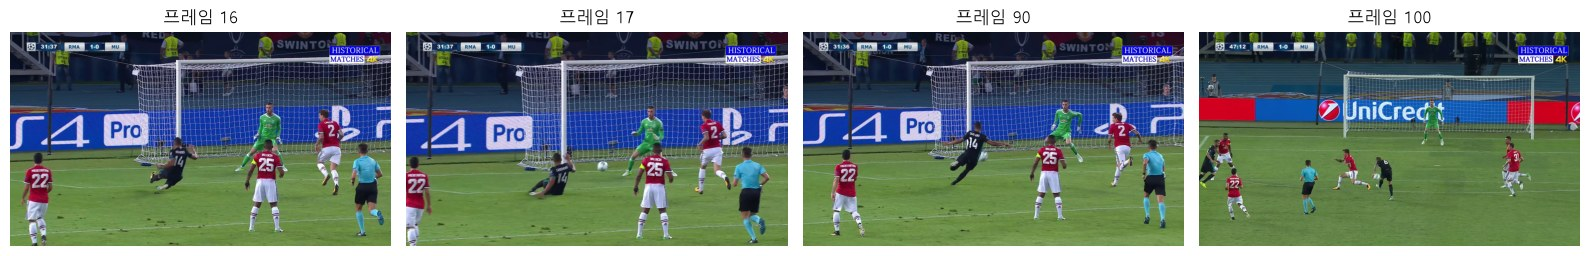

In [3]:
# 내용이 완전히 같은 파일
by_hash = {}                              # 해시값 → 파일 이름 목록
for name in files:
    # 바이트가 같으면 같은 해시
    by_hash.setdefault(hashlib.sha256((img_dir / name).read_bytes()).hexdigest(), []).append(name)
dups = [g for g in by_hash.values() if len(g) > 1]  # 2장 이상 묶인 그룹만
print("완전 중복:", dups)                 # 중복 파일 이름
files = [g[0] for g in by_hash.values()]  # 그룹마다 첫 파일만 남김 (프레임 번호 순서 유지)
print(f"중복 제외 후 {len(files)}장")     # 이후 모든 단계의 이미지 수

# 비슷한 프레임 찾기
thumbs = []                                       # 작게 줄인 흑백 이미지
for name in files:
    gray = cv2.imread(str(img_dir / name), cv2.IMREAD_GRAYSCALE)  # 밝기만 비교
    # 화면 구도만 남기도록 축소
    t = cv2.resize(gray, (64, 36), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
    thumbs.append((t - t.mean()) / t.std())       # 전체 밝기 차이 제거
thumbs = np.stack(thumbs)                         # (이미지 수, 2304)
similarity = thumbs @ thumbs.T / thumbs.shape[1]  # 두 이미지의 상관계수 (1 = 같은 구도)
SIM_THRESHOLD = 0.6                               # 이 값 이상이면 같은 장면으로 봄
# 비슷한 쌍을 이어 묶음
n_scene, scene_id = connected_components(similarity >= SIM_THRESHOLD, directed=False)
scene_of = dict(zip(files, scene_id))             # 파일 → 장면 번호
scene_size = pd.Series(scene_id).value_counts()   # 장면별 이미지 수
# 묶음 규모
print(f"장면 {n_scene}개 · 2장 이상 장면 {(scene_size > 1).sum()}개 · 가장 큰 장면 {scene_size.max()}장")

# 가장 큰 장면 확인
members = [f for f in files if scene_of[f] == scene_size.index[0]]  # 가장 큰 장면의 파일
# 번호가 떨어져 있어도 같은 장면인지 확인
print("가장 큰 장면의 프레임 번호:", [frame_no(f) for f in members])
fig, axes = plt.subplots(1, 4, figsize=(16, 2.7))                   # 4장 나란히
for ax, name in zip(axes, [members[0], members[1], members[len(members) // 2], members[-1]]):
    ax.imshow(cv2.imread(str(img_dir / name))[:, :, ::-1])          # BGR → RGB 출력
    ax.set_title(f"프레임 {frame_no(name)}")                        # 프레임 번호 표시
    ax.axis("off")                                                  # 축 숨김
plt.tight_layout()                                                  # 제목 겹침 방지
plt.show()                                                          # 그림 출력

**결과 해설**

```
완전 중복 1쌍 (프레임 14 = 71) : SHA-256이 같은 파일 → 71번 제외, 99장 사용
장면 46개 · 2장 이상 장면 14개 : 연속 프레임이 여러 장면으로 묶임
가장 큰 장면 13장              : 16~19 · 88~93 · 98~100
```

가장 큰 장면은 프레임 번호가 16과 98처럼 멀리 떨어져 있어도 같은 장면(그림의 16 · 17 · 90 · 100). 번호 순서로 자르거나 무작위로 나누면 거의 같은 화면이 train과 test에 함께 들어가 test 점수가 부풀려짐 → 2-1에서 장면 단위로 분할.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| sha256() · hexdigest() | hashlib | 내용 해시 · 16진수 문자열 | `hashlib.sha256(...).hexdigest()` |
| read_bytes() | pathlib | 파일을 바이트로 읽기 | `(img_dir / name).read_bytes()` |
| imread() · resize()<br>IMREAD_GRAYSCALE · INTER_AREA | cv2 | 흑백 읽기 · 축소<br>흑백 모드 · 평균 축소 | `cv2.imread(..., cv2.IMREAD_GRAYSCALE)`<br>`cv2.resize(gray, (64, 36), interpolation=cv2.INTER_AREA)` |
| stack() · ravel()<br>mean() · std() · @ 행렬곱 | numpy | 배열 쌓기 · 1차원 펴기<br>표준화 · 상관계수 | `np.stack(thumbs)` · `.ravel()`<br>`thumbs @ thumbs.T / thumbs.shape[1]` |
| connected_components() | scipy.sparse.csgraph | 연결된 이미지끼리 같은 번호 | `connected_components(similarity >= SIM_THRESHOLD, directed=False)` |
| Series() · value_counts() | pandas | 장면별 이미지 수 | `pd.Series(scene_id).value_counts()` |
| subplots() · imshow()<br>set_title() · axis() · tight_layout() | matplotlib | 그림 틀 · 이미지<br>제목 · 축 숨김 · 간격 | `plt.subplots(1, 4, figsize=(16, 2.7))`<br>`ax.axis("off")` |
| setdefault() | dict 메서드 | 키가 없으면 빈 목록 생성 | `by_hash.setdefault(..., []).append(name)` |
| dict() · zip() | Python 내장 함수 | 파일 → 장면 번호 | `dict(zip(files, scene_id))` |
| 컴프리헨션 · 슬라이싱 [::-1] | Python 기본 문법 | 중복 그룹 · BGR → RGB | `[g[0] for g in by_hash.values()]` |

### 1-3. 정수 마스크 만들기

**한글 요약**

- COCO 다각형을 채워 픽셀마다 클래스 번호(0 ~ 10)를 적은 **정수 마스크** 생성
- 넓은 영역부터 칠해 공 · 심판 같은 작은 물체가 덮이지 않게 함, 다각형 밖은 255(학습 · 평가 제외)
- 만든 마스크가 fuse 마스크와 같은 영역을 가리키는지 수치로 검증

<img src="images/m8_label.png" alt="fuse 색 대신 COCO 다각형으로 정수 마스크를 만드는 순서" width="837">

**실행 흐름**

1. **입력**: `ann`(다각형) · 원본 · fuse 마스크
2. **처리**: 이미지별 다각형을 면적 큰 순서로 채움 → 원본 · 마스크를 메모리에 저장 → 클래스 영역마다 fuse 색 일치율 계산
3. **저장**: `IMAGES` · `MASKS` · `IGNORE` · `colorize`
4. **출력**: 정답 없는 픽셀 비율 · fuse 일치율 · 원본 / fuse / 정수 마스크 비교 그림

정답 없는 픽셀 0.00% · 클래스 영역이 fuse 색 한 가지로 칠해진 비율 99.93%


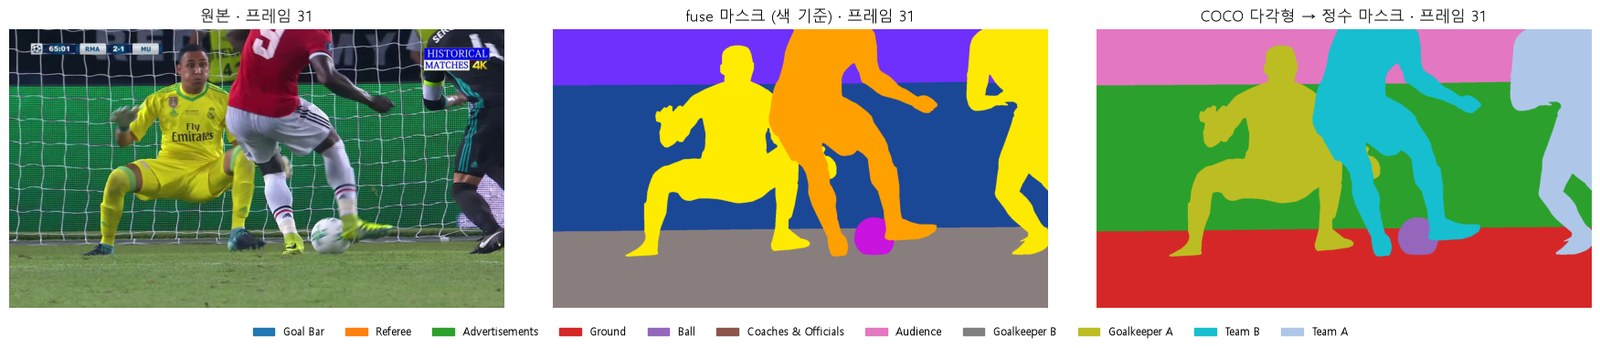

In [4]:
# 다각형 → 정수 마스크
IGNORE = 255                                           # 정답이 없는 픽셀 (학습 · 평가 제외)
info = {im["file_name"]: im for im in coco["images"]}  # 파일 이름 → 이미지 id · 크기


def coco_mask(name):
    im = info[name]                              # 이미지 id · 크기
    mask = np.full((im["height"], im["width"]), IGNORE, np.uint8)  # 처음엔 모두 '정답 없음'
    # 큰 영역부터 → 작은 물체가 위에 남음
    rows = ann[ann["image_id"] == im["id"]].sort_values("area", ascending=False)
    for cls, seg in zip(rows["class"], rows["segmentation"]):
        for poly in seg:                         # 한 물체가 여러 조각일 수 있음
            # [x1, y1, x2, y2, ...] → (점 수, 2)
            pts = np.round(np.array(poly).reshape(-1, 2)).astype(np.int32)
            cv2.fillPoly(mask, [pts], int(cls))  # 다각형 내부를 클래스 번호로 채움
    return mask


# 메모리에 한 번만 읽기
# RGB 원본 (학습 중 디스크 읽기 생략)
IMAGES = {name: cv2.imread(str(img_dir / name))[:, :, ::-1].copy() for name in files}
MASKS = {name: coco_mask(name) for name in files}  # 정수 마스크 (0 ~ 10, 255)

# fuse 마스크와 일치도
agree = total = 0                                                # 일치 픽셀 수 · 전체 정답 픽셀 수
for name in files:
    fuse, m = packed_rgb(img_dir / f"{name}___fuse.png"), MASKS[name]  # fuse 색 · 우리 마스크
    for c in np.unique(m[m != IGNORE]):
        _, counts = np.unique(fuse[m == c], return_counts=True)  # 이 클래스 영역의 fuse 색 분포
        # 가장 많은 색 하나와 일치하는 픽셀
        agree, total = agree + counts.max(), total + counts.sum()
# 정답 없는 픽셀 비율
unlabeled = sum((m == IGNORE).sum() for m in MASKS.values()) / sum(m.size for m in MASKS.values())
# 변환 결과 검증
print(f"정답 없는 픽셀 {unlabeled:.2%} · 클래스 영역이 fuse 색 한 가지로 칠해진 비율 {agree / total:.2%}")

# 원본 · fuse · 정수 마스크 비교
# 클래스별 표시 색
PALETTE = (plt.cm.tab20(np.linspace(0, 1, 20))[[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1], :3] * 255).astype(np.uint8)
COLORS = np.vstack([PALETTE, np.zeros((245, 3), np.uint8) + 255])  # 255(정답 없음)는 흰색


def colorize(mask):
    return COLORS[mask]  # 클래스 번호 → 색


# 공이 가장 크게 나온 이미지
name = max(files, key=lambda n: (MASKS[n] == CLASSES.index("Ball")).sum())
# 세 그림
panels = [IMAGES[name], cv2.imread(str(img_dir / f"{name}___fuse.png"))[:, :, ::-1], colorize(MASKS[name])]
fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))       # 나란히 비교
for ax, img, title in zip(axes, panels, ["원본", "fuse 마스크 (색 기준)", "COCO 다각형 → 정수 마스크"]):
    ax.imshow(img)                                      # 그림 출력
    ax.set_title(f"{title} · 프레임 {frame_no(name)}")  # 종류 · 프레임 표시
    ax.axis("off")                                      # 축 숨김
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[i] / 255) for i in range(11)]  # 범례 색 상자
# 클래스 색 안내
fig.legend(handles, CLASSES, loc="lower center", ncol=11, fontsize=8.5, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))                  # 범례 자리 확보
plt.show()                                              # 그림 출력

**결과 해설**

```
정답 없는 픽셀 0.00%          : 모든 픽셀이 다각형 하나 이상에 속함
fuse 색 한 가지와 일치 99.93% : 다각형 정답과 fuse가 같은 영역을 같은 클래스로 칠함
```

그림 가운데(fuse)와 오른쪽(다각형 정답)은 색 체계만 다르고 모양은 같음. 나머지 0.07%는 다각형 경계에서 두 그림의 테두리가 1~2픽셀 어긋난 부분. 면적이 큰 순서로 칠했기 때문에 Ground 위의 공(보라색 원)이 덮이지 않고 남음.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| full() · round() · reshape()<br>bincount() · unique(return_counts=True) | numpy | 255로 채운 마스크 · 좌표 정리<br>픽셀 수 · 색별 개수 | `np.full((h, w), IGNORE, np.uint8)`<br>`np.unique(fuse[m == c], return_counts=True)` |
| fillPoly() | cv2 | 다각형 내부 채우기 | `cv2.fillPoly(mask, [pts], int(cls))` |
| sort_values() | pandas | 면적 큰 순서 | `.sort_values("area", ascending=False)` |
| cm.tab20 · Rectangle<br>legend() | matplotlib | 클래스 색 · 범례 색 상자<br>그림 아래 범례 | `plt.cm.tab20(...)` · `plt.Rectangle(...)`<br>`fig.legend(handles, CLASSES, ncol=11)` |
| coco_mask() · colorize() | 사용자 정의 함수 | 다각형 → 정수 마스크 · 번호 → 색 | `MASKS = {name: coco_mask(name) ...}` |
| max(key=) · sum() | Python 내장 함수 | 공이 가장 큰 이미지 · 비율 합계 | `max(files, key=lambda n: ...)` |
| 딕셔너리 컴프리헨션<br>lambda | Python 기본 문법 | 파일별 원본 · 마스크 저장<br>정렬 기준 | `{name: coco_mask(name) for name in files}`<br>`key=lambda n: (MASKS[n] == ...).sum()` |

### 1-4. 클래스 분포

**한글 요약**

- 클래스마다 **픽셀 비율(면적)** 과 **등장 이미지 비율(빈도)** 을 함께 집계
- 정답 픽셀이 없는 클래스는 평가에서 빼고, 면적 1% 미만 클래스를 **희소 클래스**로 정의

**실행 흐름**

1. **입력**: `MASKS`
2. **처리**: 이미지별 클래스 픽셀 수 → 전체 합계 · 등장 횟수 → 평가 · 희소 클래스 선정
3. **저장**: `EVAL_CLASSES` · `RARE`
4. **출력**: 분포 표 · 면적(로그 축) / 빈도 막대그래프

,클래스,픽셀 비율(%),등장 이미지 비율(%)
3,Ground,40.907,86.869
6,Audience,24.863,93.939
2,Advertisements,15.610,95.960
9,Team B,8.097,97.980
10,Team A,6.930,97.980
0,Goal Bar,1.415,63.636
8,Goalkeeper A,1.121,38.384
7,Goalkeeper B,0.557,46.465
1,Referee,0.385,24.242
4,Ball,0.115,64.646


평가 클래스 10 개 | 제외: ['Coaches & Officials']
희소 클래스(면적 1% 미만): ['Referee', 'Ball', 'Goalkeeper B']


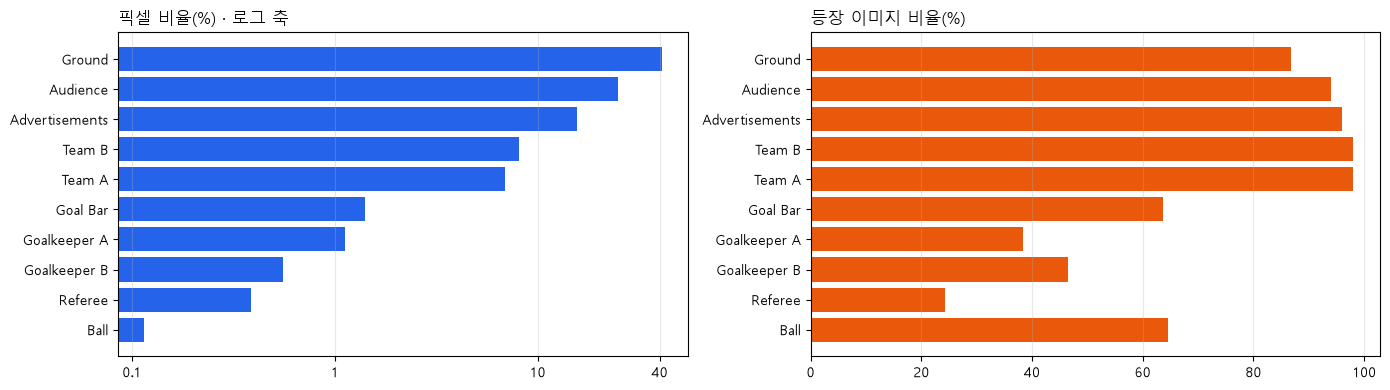

In [5]:
# 클래스별 픽셀 수 · 등장 이미지 수
pixels = np.zeros(11, np.int64)                              # 클래스별 픽셀 수
appear = np.zeros(11, np.int64)                              # 클래스가 나온 이미지 수
for m in MASKS.values():
    counts = np.bincount(m.ravel(), minlength=256)[:11]      # 이미지 한 장의 클래스별 픽셀 수
    pixels, appear = pixels + counts, appear + (counts > 0)  # 전체 합계 누적
dist = pd.DataFrame({
    "클래스": CLASSES,                                       # 클래스 이름
    "픽셀 비율(%)": pixels / pixels.sum() * 100,             # 면적 기준 불균형
    "등장 이미지 비율(%)": appear / len(files) * 100,        # 빈도 기준 불균형
}).sort_values("픽셀 비율(%)", ascending=False)              # 큰 클래스부터
display(dist.round(3))                                       # 클래스 분포 표

# 평가 · 희소 클래스 정의
EVAL_CLASSES = [c for c in range(11) if pixels[c] > 0]           # 정답 픽셀이 있는 클래스만 평가
RARE = [c for c in EVAL_CLASSES if pixels[c] / pixels.sum() < 0.01]  # 면적 1% 미만 = 희소 클래스
# 정답 없는 클래스 확인
print("평가 클래스", len(EVAL_CLASSES), "개 | 제외:", [CLASSES[c] for c in range(11) if c not in EVAL_CLASSES])
print("희소 클래스(면적 1% 미만):", [CLASSES[c] for c in RARE])  # 이후 실험의 관찰 대상

# 분포 그래프
fig, axes = plt.subplots(1, 2, figsize=(14, 4))                       # 면적 · 빈도 나란히
d = dist[dist["픽셀 비율(%)"] > 0].iloc[::-1]  # 정답 있는 클래스만 · 작은 것이 아래
axes[0].barh(d["클래스"], d["픽셀 비율(%)"], color="#2563eb")         # 면적 막대
axes[0].set_xscale("log")  # 0.1%와 40%를 한 그림에 보이도록 로그 축
axes[0].set_xticks([0.1, 1, 10, 40], ["0.1", "1", "10", "40"])        # 눈금을 보통 숫자로
axes[0].minorticks_off()                                              # 보조 눈금 숨김
axes[0].set_title("픽셀 비율(%) · 로그 축", loc="left")               # 그래프 제목
axes[1].barh(d["클래스"], d["등장 이미지 비율(%)"], color="#ea580c")  # 빈도 막대
axes[1].set_title("등장 이미지 비율(%)", loc="left")                  # 그래프 제목
for ax in axes:
    ax.grid(axis="x", alpha=0.3)                                      # 값 읽기용 옅은 격자
plt.tight_layout()                                                    # 제목 겹침 방지
plt.show()                                                            # 그래프 출력

**결과 해설**

```
Ground 40.9 · Audience 24.9 · Advertisements 15.6% : 세 클래스가 픽셀의 81%
Ball 0.115% · 등장 64.6%                           : 자주 나오지만 아주 작음
Referee 0.385% · 등장 24.2%                        : 작고 드물게 나옴
평가 클래스 10개 · 제외 Coaches & Officials        : 정답이 0픽셀인 클래스는 평균에서 뺌
희소 클래스 Referee · Ball · Goalkeeper B          : 면적 1% 미만 → 이후 실험에서 따로 추적
```

픽셀 정확도는 Ground만 맞혀도 40%를 넘으므로 쓰지 않고, 클래스마다 IoU를 구해 평균(mIoU)을 주 지표로 사용. 공은 64.6%의 이미지에 나오지만 면적은 0.1% → 픽셀 평균 손실(CE)만으로는 학습 신호가 거의 없음.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| zeros() · bincount() | numpy | 합계 배열 · 클래스별 픽셀 수 | `np.bincount(m.ravel(), minlength=256)[:11]` |
| DataFrame() · sort_values() · round() · iloc[] | pandas | 분포 표 · 정렬 · 반올림 · 순서 뒤집기 | `pd.DataFrame({...}).sort_values(...)` · `.iloc[::-1]` |
| barh() · set_xscale("log")<br>grid() | matplotlib | 가로 막대 · 로그 축<br>옅은 격자 | `axes[0].barh(...)` · `axes[0].set_xscale("log")`<br>`ax.grid(axis="x", alpha=0.3)` |
| print() · len() | Python 내장 함수 | 평가 · 희소 클래스 출력 | `print("희소 클래스(면적 1% 미만):", ...)` |
| 조건 있는 컴프리헨션 | Python 기본 문법 | 평가 · 희소 클래스 고르기 | `[c for c in EVAL_CLASSES if pixels[c] / pixels.sum() < 0.01]` |

---
## 2. 데이터 준비

### 2-1. 장면 단위 분할

**한글 요약**

- 1-2의 **장면을 쪼개지 않고** train · val · test에 배정 → 같은 장면이 학습과 평가에 함께 들어가는 누수 차단
- 장면 순서를 3,000번 섞어 후보를 만들고, val · test에 모든 평가 클래스가 있으면서 **클래스 등장률이 전체와 가장 비슷한** 후보 선택

<img src="images/m8_scene.png" alt="비슷한 장면을 묶어 train · val · test에 나누는 방식" width="837">

**실행 흐름**

1. **입력**: `scene_of` · `MASKS`
2. **처리**: 이미지별 클래스 등장 표 → 장면 순서 섞기 → val 15 · test 15장 채우기 → 조건 확인 → 등장률 차이 최소 후보
3. **저장**: `split` (train · val · test 파일 목록)
4. **출력**: 분할별 이미지 · 장면 수와 클래스별 등장 이미지 수

In [6]:
# 이미지별 클래스 등장 여부
presence = pd.DataFrame([np.bincount(MASKS[n].ravel(), minlength=256)[:11] > 0 for n in files],
                        # (이미지, 평가 클래스) 참/거짓
                        index=files, columns=CLASSES)[[CLASSES[c] for c in EVAL_CLASSES]]
scenes = sorted(set(scene_of.values()))  # 장면 번호 목록
scene_files = {s: [f for f in files if scene_of[f] == s] for s in scenes}  # 장면 → 파일
TARGET = {"val": 15, "test": 15}         # 약 15%씩, 나머지는 train

# 장면 단위 분할 후보 탐색
rng = np.random.default_rng(SEED)               # 후보 생성 난수
best_score, split = np.inf, None                # 가장 좋은 후보
for trial in range(3000):
    count, part_of = {"val": 0, "test": 0}, {}  # 후보 하나의 배정 결과
    for s in rng.permutation(scenes):           # 장면 순서를 섞어 차례로 배정
        n = len(scene_files[s])                 # 장면 크기
        # 자리가 남은 쪽으로
        part_of[s] = next((p for p in TARGET if count[p] + n <= TARGET[p]), "train")
        if part_of[s] != "train":
            count[part_of[s]] += n              # 배정된 이미지 수 누적
    if count != TARGET:
        continue                                # 정확히 15장씩이 아니면 버림
    # 파일 목록
    parts = {p: [f for f in files if part_of[scene_of[f]] == p] for p in ["train", "val", "test"]}
    if (presence.loc[parts["val"]].sum() == 0).any() or (presence.loc[parts["test"]].sum() == 0).any():
        continue                                # val · test에 없는 클래스가 있으면 평가 불가
    # 전체와 다른 정도
    score = sum((presence.loc[parts[p]].mean() - presence.mean()).abs().mean() for p in parts)
    if score < best_score:
        best_score, split = score, parts        # 클래스 구성이 전체와 가장 비슷한 후보

# 분할 결과
# 장면이 섞이지 않음
assert not set(map(scene_of.get, split["train"])) & set(map(scene_of.get, split["val"] + split["test"]))
# 규모
summary = pd.DataFrame({p: {"이미지": len(v), "장면": len(set(map(scene_of.get, v)))} for p, v in split.items()})
# 클래스별 등장 이미지 수
display(pd.concat([summary, pd.DataFrame({p: presence.loc[v].sum() for p, v in split.items()})]))
print(f"평가한 후보 3,000개 · 선택한 후보의 등장률 차이 {best_score:.3f}")  # 분할 품질 지표
print("✅ train · val · test 장면 겹침 없음")                               # 누수 차단 확인

,train,val,test
이미지,69,15,15
장면,25,13,8
Goal Bar,45,9,9
Referee,16,5,3
Advertisements,67,14,14
Ground,57,14,15
Ball,43,9,12
Audience,66,14,13
Goalkeeper B,31,8,7
Goalkeeper A,27,5,6


평가한 후보 3,000개 · 선택한 후보의 등장률 차이 0.111
✅ train · val · test 장면 겹침 없음


**결과 해설**

```
후보 3,000개 · 등장률 차이 0.111              : 클래스 등장 비율이 전체와 가장 가까운 분할 선택
train 69장(장면 25) · val 15(13) · test 15(8) : 장면을 쪼개지 않고 배정
Referee 16 · 5 · 3장                          : 가장 드문 클래스도 세 분할 모두에 들어감
Team A · B 15 · 15                            : val · test 모든 이미지에 선수 있음
장면 겹침 없음                                : 같은 장면이 두 분할에 걸치지 않음
```

test는 15장(8개 장면)뿐 → 4-1에서 이미지 단위 부트스트랩으로 신뢰구간을 함께 보고.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| default_rng() · permutation() | numpy.random | 난수 생성기 · 장면 순서 섞기 | `rng.permutation(scenes)` |
| DataFrame() · loc[] · sum() · mean()<br>abs() · concat() | pandas | 등장 표 · 행 고르기 · 등장 수 · 등장률<br>차이 크기 · 표 붙이기 | `presence.loc[parts["val"]].sum()`<br>`pd.concat([summary, ...])` |
| next() · map() · set() | Python 내장 함수 | 자리가 남은 첫 분할 · 장면 번호 변환 · 겹침 확인 | `next((p for p in TARGET if ...), "train")`<br>`set(map(scene_of.get, split["train"]))` |
| continue · assert<br>&amp; 집합 교집합 | Python 기본 문법 | 조건 미달 후보 건너뛰기 · 누수 검사<br>공통 장면 찾기 | `if count != TARGET: continue`<br><code>assert not set(...) &amp; set(...)</code> |

### 2-2. Dataset · 증강 · DataLoader

**한글 요약**

- 원본 1920×1080을 통째로 학습하면 GPU 메모리가 부족 → 학습은 **512×512 무작위 조각**, 평가는 원본 그대로
- 증강: 0.75 ~ 1.25배 크기 변화 · 좌우 반전 · 밝기 · 대비 변화 (정답은 번호가 섞이지 않게 최근접 보간)
- `rare_focus` 확률만큼 **희소 클래스 픽셀이 들어간 위치**를 잘라 작은 물체를 더 자주 보여 줌 (3-6 실험용)

<img src="images/m8_crop.png" alt="512 조각 학습과 원본 크기 평가, 증강 목록" width="837">

**실행 흐름**

1. **입력**: `IMAGES` · `MASKS` · `RARE`
2. **처리**: 희소 클래스 좌표 미리 저장 → 위치 고르기(무작위 또는 희소 클래스 중심) → 자르기 · 크기 맞추기 → 반전 · 밝기 → ImageNet 정규화
3. **저장**: `FootballDataset` · `CROP` · `MEAN` · `STD`
4. **출력**: 배치 모양 · 학습 조각 4개와 정답

입력 (4, 3, 512, 512) torch.float32 | 정답 (4, 512, 512) torch.int64 | 정답 값 [0, 1, 2, 3, 4, 6, 7, 8, 9, 10]
✅ 통과


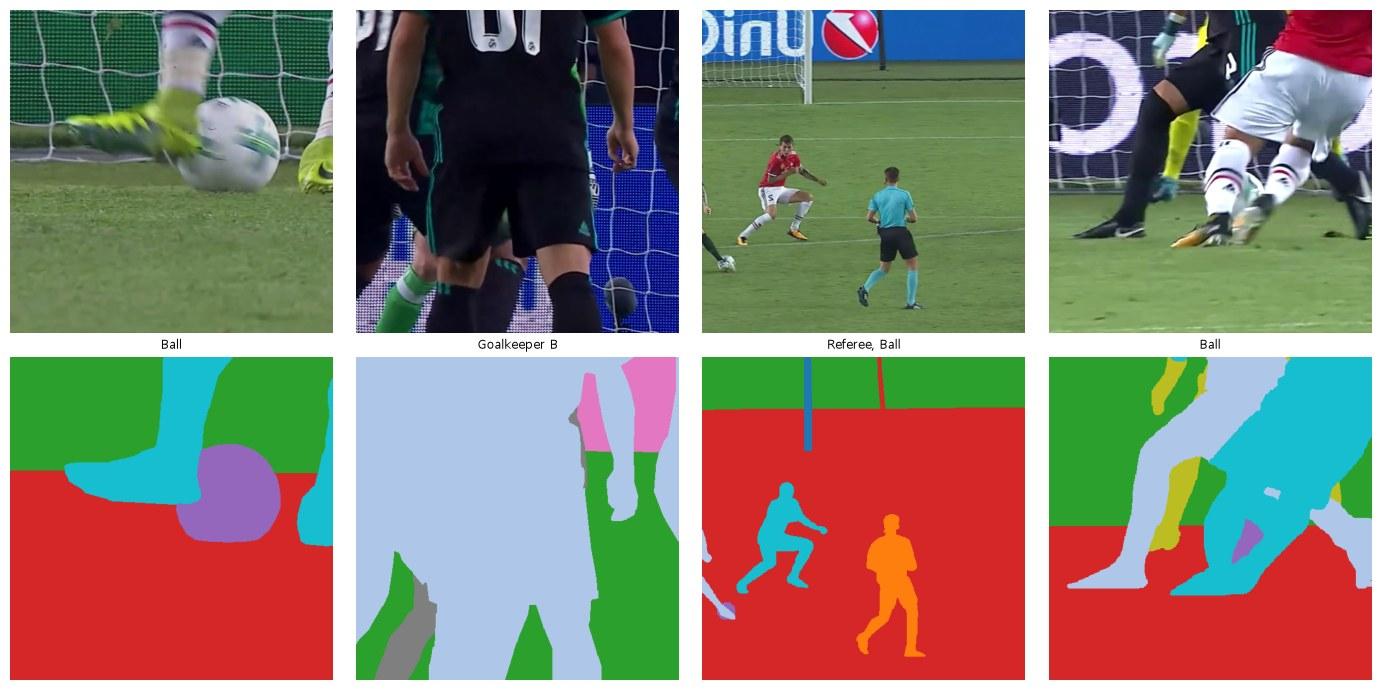

In [7]:
# 입력 설정
CROP = 512  # 학습 조각 크기 (원본 1920×1080 전체는 GPU 메모리 부족)
MEAN = np.array([0.485, 0.456, 0.406], np.float32)  # ImageNet 평균 (사전학습 인코더와 같은 기준)
STD = np.array([0.229, 0.224, 0.225], np.float32)   # ImageNet 표준편차
# 희소 클래스 픽셀 좌표 (25개 중 1개)
RARE_POINTS = {n: np.argwhere(np.isin(MASKS[n], RARE))[::25] for n in files}


class FootballDataset(Dataset):
    def __init__(self, names, train, crops_per_image=1, rare_focus=0.0):
        self.names, self.train = names, train  # 파일 목록 · 학습용 여부
        # 이미지당 조각 수 · 희소 클래스 중심 확률
        self.k, self.rare_focus = crops_per_image, rare_focus

    def __len__(self):
        return len(self.names) * self.k  # 한 epoch에 이미지마다 k조각

    def __getitem__(self, i):
        name = self.names[i % len(self.names)]                 # k번 반복해서 같은 이미지 사용
        image, mask = IMAGES[name], MASKS[name]                # 메모리의 원본 · 정답
        if self.train:
            image, mask = self.augment(image, mask, RARE_POINTS[name])  # 학습만 무작위 변형
        image = (image.astype(np.float32) / 255 - MEAN) / STD  # 0 ~ 1 → ImageNet 정규화
        # (3, H, W) · (H, W)
        return torch.from_numpy(image.transpose(2, 0, 1).copy()), torch.from_numpy(mask.astype(np.int64))

    def augment(self, image, mask, rare_points):
        # 자를 크기 (512로 맞추면 0.75 ~ 1.25배 확대 · 축소)
        size = int(CROP / random.uniform(0.75, 1.25))
        h, w = mask.shape                                # 1080, 1920
        if len(rare_points) and random.random() < self.rare_focus:
            cy, cx = rare_points[random.randrange(len(rare_points))]  # 희소 클래스 픽셀 하나를 고름
            # 그 픽셀이 조각 안에 들도록
            y0 = int(np.clip(cy - random.randint(size // 4, 3 * size // 4), 0, h - size))
            # 가운데만 오지 않게 위치 흔듦
            x0 = int(np.clip(cx - random.randint(size // 4, 3 * size // 4), 0, w - size))
        else:
            y0, x0 = random.randint(0, h - size), random.randint(0, w - size)  # 아무 위치
        # 원본은 부드럽게
        image = cv2.resize(image[y0:y0 + size, x0:x0 + size], (CROP, CROP), interpolation=cv2.INTER_LINEAR)
        # 정답은 번호 유지
        mask = cv2.resize(mask[y0:y0 + size, x0:x0 + size], (CROP, CROP), interpolation=cv2.INTER_NEAREST)
        if random.random() < 0.5:
            image, mask = image[:, ::-1], mask[:, ::-1]  # 좌우 반전 (공격 방향과 무관하게)
        # 대비 · 밝기 변화 (조명 차이)
        image = np.clip(image * random.uniform(0.8, 1.2) + random.uniform(-20, 20), 0, 255)
        return image, mask


# 학습 조각 확인
set_seed(SEED)                                                        # 같은 조각이 나오도록
sample = FootballDataset(split["train"], train=True, rare_focus=1.0)  # 희소 클래스 중심 조각
x, y = next(iter(DataLoader(sample, batch_size=4, shuffle=True)))     # 조각 4개
# 모양 · 값 확인
print("입력", tuple(x.shape), x.dtype, "| 정답", tuple(y.shape), y.dtype, "| 정답 값", sorted(y.unique().tolist()))
assert x.shape == (4, 3, CROP, CROP) and y.shape == (4, CROP, CROP)   # 모델 입력 크기 확인
print("✅ 통과")
fig, axes = plt.subplots(2, 4, figsize=(14, 7))                       # 위 원본 · 아래 정답
for k in range(4):
    # 정규화 되돌려 출력
    axes[0, k].imshow(np.clip(x[k].numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1))
    axes[1, k].imshow(colorize(y[k].numpy()))                         # 정답 색 표시
    # 들어간 희소 클래스
    axes[1, k].set_title(", ".join(CLASSES[c] for c in RARE if (y[k] == c).any()) or "희소 클래스 없음", fontsize=9)
for ax in axes.flat:
    ax.axis("off")                                                    # 축 숨김
plt.tight_layout()                                                    # 제목 겹침 방지
plt.show()                                                            # 그림 출력

**결과 해설**

```
입력 (4, 3, 512, 512) float32 : 배치 4 · RGB · 512×512 조각
정답 (4, 512, 512) int64      : 픽셀마다 클래스 번호
정답 값 0~10 (5 없음)         : Coaches & Officials(5)는 정답이 없어 등장하지 않음
```

그림은 `rare_focus=1.0`(모든 조각을 희소 클래스 중심으로)으로 뽑은 4개. 원본 1920×1080에서는 점처럼 작은 공이 조각 안에서는 크게 잡히고, 두 줄 사이 제목처럼 조각마다 희소 클래스가 하나 이상 들어감.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Dataset · DataLoader | torch.utils.data | 샘플 정의 · 배치 묶기 | `class FootballDataset(Dataset)`<br>`DataLoader(sample, batch_size=4, shuffle=True)` |
| from_numpy() | torch | 배열 → 텐서 (복사 없이) | `torch.from_numpy(image.transpose(2, 0, 1).copy())` |
| resize()<br>INTER_LINEAR · INTER_NEAREST | cv2 | 조각을 512로<br>원본 부드럽게 · 정답 번호 유지 | `cv2.resize(..., (CROP, CROP), interpolation=cv2.INTER_NEAREST)` |
| argwhere() · isin() · clip()<br>transpose() | numpy | 희소 클래스 좌표 · 범위 제한<br>(H, W, 3) → (3, H, W) | `np.argwhere(np.isin(MASKS[n], RARE))[::25]`<br>`np.clip(cy - ..., 0, h - size)` |
| uniform() · randint() · random() · randrange() | random | 배율 · 위치 · 확률 · 좌표 하나 | `random.uniform(0.75, 1.25)` |
| __init__() · __len__() · __getitem__()<br>augment() | 사용자 정의 클래스 | 설정 · 샘플 수 · i번째 샘플<br>자르기 · 반전 · 밝기 | `len(self.names) * self.k`<br>`self.augment(image, mask, RARE_POINTS[name])` |
| next() · iter() · sorted() | Python 내장 함수 | 첫 배치 꺼내기 · 정답 값 정렬 | `next(iter(DataLoader(...)))` |
| % 나머지 · 조건 표현식 | Python 기본 문법 | k번 반복 · 희소 클래스 없을 때 문구 | `self.names[i % len(self.names)]` |

---
## 3. 모델과 학습

### 3-1. 비교할 모델 2종

**한글 요약**

- **기준선**: 처음부터 학습하는 U-Net (인코더 3단 · 병목 · 디코더 3단 · 스킵 연결, 합성곱마다 BatchNorm)
- **사전학습 모델**: ImageNet으로 학습된 EfficientNet-B0 인코더 + **U-Net++** 디코더 (스킵 연결 사이에 합성곱을 겹겹이 넣어 인코더 · 디코더 특징 차이를 줄임)
- 두 모델 모두 원본 크기(32배수 패딩) 입력에서 같은 크기의 클래스 점수가 나오는지 확인

<img src="images/m8_model.png" alt="U-Net과 U-Net++의 스킵 연결 차이" width="837">

**실행 흐름**

1. **입력**: 클래스 수 11
2. **처리**: U-Net 정의 → 모델 생성 함수 → 모델별 파라미터 수 · 출력 모양 확인
3. **저장**: `UNet` · `build_model`
4. **출력**: 파라미터 수 · 출력 모양

In [8]:
# 기준선: 직접 구현한 U-Net (BatchNorm 포함)
def conv_block(c_in, c_out):
    return nn.Sequential(
        # 3×3 합성곱 → 정규화 → 활성화
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        # 한 번 더 (특징 강화)
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, num_classes=11):
        super().__init__()
        # 인코더 3단
        self.enc1, self.enc2, self.enc3 = conv_block(3, 64), conv_block(64, 128), conv_block(128, 256)
        self.pool = nn.MaxPool2d(2)                # 크기 절반 (넓은 범위를 보도록)
        self.bottleneck = conv_block(256, 512)     # 가장 작은 해상도의 특징
        # 크기 2배 + 스킵 결합
        self.up3, self.dec3 = nn.ConvTranspose2d(512, 256, 2, stride=2), conv_block(512, 256)
        # 크기 2배 + 스킵 결합
        self.up2, self.dec2 = nn.ConvTranspose2d(256, 128, 2, stride=2), conv_block(256, 128)
        # 크기 2배 + 스킵 결합
        self.up1, self.dec1 = nn.ConvTranspose2d(128, 64, 2, stride=2), conv_block(128, 64)
        self.head = nn.Conv2d(64, num_classes, 1)  # 픽셀마다 클래스 점수 11개

    def forward(self, x):
        e1 = self.enc1(x)                                     # 원래 크기
        e2 = self.enc2(self.pool(e1))                         # 1/2
        e3 = self.enc3(self.pool(e2))                         # 1/4
        b = self.bottleneck(self.pool(e3))                    # 1/8
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))   # 1/4 · 위치 정보 복원
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))  # 1/2
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))  # 원래 크기
        return self.head(d1)                                  # (배치, 11, H, W)


# 모델 생성 함수
def build_model(kind):
    if kind == "U-Net (직접 구현)":
        return UNet(len(CLASSES))  # 가중치 무작위 시작
    # ImageNet 사전학습 인코더
    return smp.UnetPlusPlus(encoder_name="efficientnet-b0", encoder_weights="imagenet", classes=len(CLASSES))


# 구조 확인
for kind in ["U-Net (직접 구현)", "U-Net++ (EfficientNet-B0)"]:
    m = build_model(kind).to(device).eval()  # 모델 생성
    with torch.no_grad(), torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
        # 평가 때 쓰는 원본 크기(32배수로 패딩)
        out = m(torch.zeros(1, 3, 1088, 1920, device=device))
    # 크기 · 출력 모양
    print(f"{kind:<26} 파라미터 {sum(p.numel() for p in m.parameters()) / 1e6:.2f}M | 출력 {tuple(out.shape)}")
    assert out.shape == (1, 11, 1088, 1920)  # 입력과 같은 크기의 클래스 점수
print("✅ 통과")
del m, out                                   # 메모리 정리
torch.cuda.empty_cache()                     # GPU 메모리 반환

U-Net (직접 구현)              파라미터 7.70M | 출력 (1, 11, 1088, 1920)


U-Net++ (EfficientNet-B0)  파라미터 6.57M | 출력 (1, 11, 1088, 1920)
✅ 통과


**결과 해설**

```
U-Net (직접 구현)     7.70M     : 인코더 3단 · 병목 · 디코더 3단, 무작위 초깃값
U-Net++ (EfficientNet-B0) 6.57M : ImageNet 사전학습 인코더, 파라미터는 오히려 적음
출력 (1, 11, 1088, 1920)        : 클래스 11개 점수 · 높이 1080 → 32의 배수 1088로 채워 입력
```

두 모델 모두 1088×1920 전체 크기를 한 번에 처리 → 평가 때 조각으로 나눠 합칠 필요 없음.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Module · Sequential<br>Conv2d · BatchNorm2d · ReLU<br>MaxPool2d · ConvTranspose2d | torch.nn | 모델 틀 · 층 묶기<br>합성곱 · 정규화 · 활성화<br>크기 절반 · 크기 2배 | `class UNet(nn.Module)`<br>`nn.Conv2d(c_in, c_out, 3, padding=1)`<br>`nn.ConvTranspose2d(512, 256, 2, stride=2)` |
| cat() · zeros() · no_grad() · autocast() | torch | 스킵 결합 · 확인용 입력 · 기울기 끄기 · fp16 계산 | `torch.cat([self.up3(b), e3], dim=1)`<br>`torch.zeros(1, 3, 1088, 1920, device=device)` |
| UnetPlusPlus() | segmentation_models_pytorch | 사전학습 인코더 + U-Net++ 디코더 | `smp.UnetPlusPlus(encoder_name="efficientnet-b0", encoder_weights="imagenet", classes=11)` |
| parameters() · numel() · eval() · to() | torch.nn.Module · torch.Tensor | 파라미터 수 · 평가 모드 · 장치 이동 | `sum(p.numel() for p in m.parameters())` |
| conv_block() · build_model() | 사용자 정의 함수 | 합성곱 2번 묶음 · 이름으로 모델 생성 | `build_model(kind).to(device).eval()` |
| super().__init__() · forward() | Python 클래스 문법 | 부모 초기화 · 순전파 정의 | `super().__init__()` |
| del · assert | Python 기본 문법 | 메모리 정리 · 출력 모양 검사 | `assert out.shape == (1, 11, 1088, 1920)` |

### 3-2. 손실 함수와 평가 지표

**한글 요약**

- **CE**: 픽셀마다 정답 클래스 확률을 높임 → 면적이 큰 클래스가 손실을 주도
- **Dice**: 클래스마다 예측과 정답이 **겹친 비율**을 높임 → 작은 클래스도 같은 비중
- **가중 CE**: 클래스가 나왔을 때 차지하는 면적이 작을수록 큰 가중치(중앙값 ÷ 빈도, 상한 10, train만 사용)
- **평가**: 혼동 행렬 하나로 IoU · Dice · precision · recall 계산, 정답 있는 10개 클래스 평균 = **mIoU**

<img src="images/m8_metric.png" alt="CE · Dice · 가중 CE의 역할과 IoU · Dice 계산" width="837">

**실행 흐름**

1. **입력**: train 마스크 · 예측 / 정답 텐서
2. **처리**: 클래스 가중치 → Dice 손실 → 손실 조합 → 혼동 행렬 → 지표 → 작은 예시로 검증
3. **저장**: `WEIGHTS` · `SegLoss` · `confusion` · `scores`
4. **출력**: 클래스별 가중치 · 검증 통과

In [9]:
# 클래스 가중치 (median frequency balancing, train만 사용)
def class_weights(names, max_weight=10.0):
    pix = np.zeros(11)      # 클래스별 픽셀 수
    img_pix = np.zeros(11)  # 그 클래스가 나온 이미지들의 전체 픽셀 수
    for n in names:
        # 이미지 한 장의 클래스별 픽셀 수
        counts = np.bincount(MASKS[n].ravel(), minlength=256)[:11]
        # 나온 이미지에서만 빈도 계산
        pix, img_pix = pix + counts, img_pix + (counts > 0) * MASKS[n].size
    freq = np.divide(pix, img_pix, out=np.zeros(11), where=img_pix > 0)  # 나왔을 때 차지하는 면적
    weights = np.zeros(11)  # 정답 없는 클래스는 0
    # 작을수록 크게 · 상한 10
    weights[EVAL_CLASSES] = np.minimum(np.median(freq[EVAL_CLASSES]) / freq[EVAL_CLASSES], max_weight)
    return torch.tensor(weights, dtype=torch.float32)


# Dice 손실 (겹친 정도를 직접 최대화)
class DiceLoss(nn.Module):
    def forward(self, logits, target):
        prob = logits.float().softmax(dim=1)                  # 클래스 확률 (fp16 오차 방지로 float)
        valid = (target != IGNORE).unsqueeze(1)               # 정답 있는 픽셀만
        onehot = F.one_hot(target.clamp(max=10), 11).permute(0, 3, 1, 2)  # (B, 11, H, W) 정답
        inter = (prob * onehot * valid).sum(dim=(0, 2, 3))    # 클래스별 겹친 양
        union = ((prob + onehot) * valid).sum(dim=(0, 2, 3))  # 클래스별 예측 + 정답 양
        present = onehot.mul(valid).sum(dim=(0, 2, 3)) > 0    # 배치에 나온 클래스만 평균
        return 1 - (2 * inter / (union + 1e-6))[present].mean()  # 0 = 완벽히 겹침


# 손실 조합
class SegLoss(nn.Module):
    def __init__(self, name, weights):
        super().__init__()
        # 픽셀별 분류 손실
        self.ce = nn.CrossEntropyLoss(weight=weights if "가중" in name else None, ignore_index=IGNORE)
        self.dice = DiceLoss() if "Dice" in name else None  # 이름에 Dice가 있을 때만

    def forward(self, logits, target):
        ce = self.ce(logits.float(), target)  # 255 픽셀은 제외
        # 두 손실 같은 비중
        return ce if self.dice is None else 0.5 * ce + 0.5 * self.dice(logits, target)


# 혼동 행렬 · 지표
def confusion(pred, target):
    valid = target != IGNORE  # 정답 있는 픽셀만
    # 행 정답 · 열 예측
    return torch.bincount(target[valid] * 11 + pred[valid], minlength=121).reshape(11, 11).cpu()


def scores(cm):
    cm = cm.double()                                     # 큰 수 나눗셈 정확도
    tp, gt, pr = cm.diag(), cm.sum(1), cm.sum(0)         # 맞힘 · 정답 수 · 예측 수
    iou, dice = tp / (gt + pr - tp), 2 * tp / (gt + pr)  # 클래스별 IoU · Dice
    # 평가 클래스 평균
    return {"mIoU": iou[EVAL_CLASSES].mean().item(), "mDice": dice[EVAL_CLASSES].mean().item(),
            "IoU": iou, "Dice": dice, "precision": tp / pr, "recall": tp / gt}  # 클래스별 지표


# 동작 확인
WEIGHTS = class_weights(split["train"])                               # train 기준 클래스 가중치
display(pd.Series(WEIGHTS.numpy(), index=CLASSES).round(3).to_frame("가중치").T)  # 클래스별 가중치
t = torch.tensor([[0, 1, 255], [3, 3, 1]])                            # 작은 예시 정답
assert scores(confusion(t.clone(), t))["IoU"][[0, 1, 3]].eq(1).all()  # 정답 그대로면 IoU 1
# 정답 그대로면 Dice 손실 0
assert DiceLoss()(F.one_hot(t.clamp(max=10), 11).permute(2, 0, 1)[None].float() * 50, t[None]) < 1e-3
print("✅ 통과")

,Goal Bar,Referee,Advertisements,Ground,Ball,Coaches & Officials,Audience,Goalkeeper B,Goalkeeper A,Team B,Team A
가중치,1.973,3.114,0.308,0.11,10.0,0.0,0.175,4.576,1.681,0.569,0.712


✅ 통과


**결과 해설**

```
Ball 10.0 (상한)                 : 면적이 가장 작아 가중치 상한에 걸림
Goalkeeper B 4.58 · Referee 3.11 : 희소 클래스에 큰 가중치
Ground 0.11 · Audience 0.18      : 큰 클래스는 1보다 작게
Coaches & Officials 0            : 정답이 없는 클래스는 손실에서 제외
```

가중치는 train 69장의 픽셀 빈도로만 계산 (val · test 정보 사용 안 함). 중앙값 ÷ 빈도라서 중간 크기 클래스(Goal Bar 1.97)는 1 근처.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| CrossEntropyLoss(weight=, ignore_index=) | torch.nn | 가중 · 255 제외 픽셀 분류 손실 | `nn.CrossEntropyLoss(weight=..., ignore_index=IGNORE)` |
| one_hot() | torch.nn.functional | 정답 번호 → 11채널 | `F.one_hot(target.clamp(max=10), 11)` |
| softmax() · permute() · clamp()<br>bincount() · diag() · sum(dim=) | torch.Tensor · torch | 확률 · 축 순서 · 255 임시 처리<br>혼동 행렬 · 맞힘 · 축별 합 | `logits.float().softmax(dim=1)`<br>`torch.bincount(target[valid] * 11 + pred[valid], minlength=121)` |
| median() · minimum() · divide(where=) | numpy | 가중치 기준 · 상한 · 0 나눗셈 방지 | `np.minimum(np.median(...) / freq[...], max_weight)` |
| DiceLoss · SegLoss | 사용자 정의 클래스 | 겹침 손실 · 실험별 손실 조합 | `SegLoss(loss_name, WEIGHTS.to(device))` |
| class_weights() · confusion() · scores() | 사용자 정의 함수 | 클래스 가중치 · 혼동 행렬 · 지표 | `scores(confusion(t.clone(), t))` |
| 조건 표현식 · in 연산<br>** 딕셔너리 펼치기 · assert | Python 기본 문법 | 이름으로 손실 고르기<br>지표 묶기 · 검증 | `DiceLoss() if "Dice" in name else None`<br>`assert scores(...)["IoU"][[0, 1, 3]].eq(1).all()` |

### 3-3. 학습 · 평가 함수

**한글 요약**

- 모든 실험에 같은 조건: AdamW(lr 0.001) · 코사인 학습률 · 혼합 정밀도 · **40 epoch** · 배치 8 · 이미지당 조각 4개
- epoch마다 val 15장을 **원본 크기로** 평가해 검증 mIoU가 가장 높은 시점의 가중치로 복원
- 실험 결과는 `RESULTS`에 모아 두고 표 · 곡선 · 최종 선택에 재사용

**실행 흐름**

1. **입력**: `split` · `build_model` · `SegLoss`
2. **처리**: 32배수 패딩 예측 → 이미지별 혼동 행렬 → 학습 반복(순전파 · 역전파 · 학습률 조정) → epoch마다 검증 → 최고 시점 복원
3. **저장**: `predict` · `evaluate` · `train` · `run` · `RESULTS` · `rare_table`
4. **출력**: 없음 (함수 정의)

In [10]:
# 학습 설정
EPOCHS = 40          # 최대 학습 횟수
BATCH = 8            # 한 번에 학습할 조각 수
CROPS_PER_IMAGE = 4  # 한 epoch에 이미지마다 다른 위치 4조각


# 원본 크기 예측
def predict(model, x):
    h, w = x.shape[-2:]                 # 1080, 1920
    # 32배수로 패딩 (U-Net++는 1/32까지 줄임)
    x = F.pad(x, (0, -w % 32, 0, -h % 32), mode="reflect")
    with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
        logits = model(x)               # 혼합 정밀도로 빠르게
    return logits[..., :h, :w].float()  # 패딩 부분 잘라냄


def evaluate(model, names):
    model.eval()                                       # BatchNorm · Dropout 평가 모드
    cms = {}                                           # 이미지별 혼동 행렬
    data = FootballDataset(names, train=False)         # 원본 크기 그대로
    with torch.no_grad():
        for i, name in enumerate(names):
            x, y = data[i]                             # i번째 이미지 · 정답
            pred = predict(model, x[None].to(device)).argmax(1)[0]  # 픽셀마다 점수가 가장 큰 클래스
            cms[name] = confusion(pred, y.to(device))  # 이미지별로 저장 (분석 · 부트스트랩용)
    return cms


# 학습 함수
def train(kind, loss_name, seed=SEED, rare_focus=0.0):
    set_seed(seed)                                           # 실험마다 같은 조건에서 시작
    model = build_model(kind).to(device)                     # 새 모델
    # 학습 조각
    data = FootballDataset(split["train"], train=True, crops_per_image=CROPS_PER_IMAGE, rare_focus=rare_focus)
    loader = DataLoader(data, batch_size=BATCH, shuffle=True, drop_last=True,
                        generator=torch.Generator().manual_seed(seed))  # 섞는 순서도 시드로 고정
    criterion = SegLoss(loss_name, WEIGHTS.to(device))       # 실험별 손실
    # 가중치 감쇠로 과적합 완화
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    # 학습률을 0까지 서서히
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(loader))
    scaler = torch.amp.GradScaler(enabled=device == "cuda")  # fp16 기울기 소실 방지
    best, rows, start = -1.0, [], time.time()                # 최고 검증 mIoU · 기록 · 시작 시각
    for epoch in range(1, EPOCHS + 1):
        model.train()                                        # 학습 모드
        total = 0.0                                          # epoch 손실 합
        for x, y in loader:
            x, y = x.to(device), y.to(device)                # GPU로 이동
            with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
                loss = criterion(model(x), y)                # 순전파 · 손실
            optimizer.zero_grad()                            # 이전 기울기 삭제
            scaler.scale(loss).backward()                    # 역전파
            scaler.step(optimizer)                           # 가중치 갱신
            scaler.update()                                  # 배율 조정
            scheduler.step()                                 # 학습률 조정 (배치마다)
            total += loss.item()                             # 손실 누적
        val = scores(sum(evaluate(model, split["val"]).values()))  # 검증 15장 전체 지표
        # 곡선 기록
        rows.append({"epoch": epoch, "train_loss": total / len(loader), "val_mIoU": val["mIoU"]})
        if val["mIoU"] > best:
            best, best_epoch = val["mIoU"], epoch            # 최고 기록 갱신
            best_state = copy.deepcopy(model.state_dict())   # 그 시점 가중치 보관
    model.load_state_dict(best_state)                        # 최고 검증 시점으로 복원
    return model, pd.DataFrame(rows), best_epoch, (time.time() - start) / 60


# 실험 기록
RESULTS = {}  # 실험 이름 → 모델 · 곡선 · 검증 지표


def run(name, kind, loss_name, seed=SEED, rare_focus=0.0):
    model, history, best_epoch, minutes = train(kind, loss_name, seed, rare_focus)  # 학습
    val_cms = evaluate(model, split["val"])  # 최고 시점 모델의 검증 결과
    RESULTS[name] = {"model": model.cpu(), "history": history, "best_epoch": best_epoch, "minutes": minutes,
                     # GPU 메모리 비움
                     "val": scores(sum(val_cms.values())), "kind": kind, "loss": loss_name, "rare_focus": rare_focus}
    torch.cuda.empty_cache()                 # 다음 실험 메모리 확보
    r = RESULTS[name]                        # 방금 결과
    # 진행 상황
    print(f"{name:<28} 검증 mIoU {r['val']['mIoU']:.4f} (최고 {best_epoch}/{EPOCHS} epoch) · 학습 {minutes:.1f}분")


def rare_table(names):
    rows = {n: {"검증 mIoU": RESULTS[n]["val"]["mIoU"], **{CLASSES[c]: RESULTS[n]["val"]["IoU"][c].item() for c in RARE}}
            for n in names}               # 실험별 mIoU · 희소 클래스 IoU
    return pd.DataFrame(rows).T.round(4)  # 실험이 행

**결과 해설**

```
출력 없음 : 함수 정의만 하는 셀, 실제 학습은 3-4부터
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| pad(mode="reflect") | torch.nn.functional | 32배수 패딩 | `F.pad(x, (0, -w % 32, 0, -h % 32), mode="reflect")` |
| AdamW · lr_scheduler.CosineAnnealingLR | torch.optim | 가중치 감쇠 Adam · 코사인 학습률 | `torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)` |
| autocast() · amp.GradScaler<br>no_grad() · Generator().manual_seed() | torch | fp16 계산 · 기울기 배율<br>평가 · 섞는 순서 고정 | `torch.autocast(device, dtype=torch.float16, ...)`<br>`scaler.scale(loss).backward()` |
| train() · eval() · state_dict() · load_state_dict() | torch.nn.Module | 모드 전환 · 가중치 저장 · 복원 | `model.load_state_dict(best_state)` |
| zero_grad() · step() · backward() · item() | torch.optim · torch.Tensor | 기울기 초기화 · 갱신 · 역전파 · 숫자 꺼내기 | `optimizer.zero_grad()` |
| deepcopy() | copy | 최고 시점 가중치 복사본 | `copy.deepcopy(model.state_dict())` |
| time() | time | 학습 시간 | `(time.time() - start) / 60` |
| predict() · evaluate() · train() · run() · rare_table() | 사용자 정의 함수 | 원본 크기 예측 · 이미지별 평가 · 학습 · 기록 · 비교표 | `run(name, kind, loss_name, seed, rare_focus)` |
| sum() · enumerate() | Python 내장 함수 | 혼동 행렬 합 · 순번 | `sum(evaluate(model, split["val"]).values())` |
| with · 여러 값 반환<br>음수 나머지 | Python 기본 문법 | 범위 지정 실행 · 결과 4개<br>32배수까지 남은 칸 | `return model, pd.DataFrame(rows), best_epoch, ...`<br>`-w % 32` |

### 3-4. 실험 1 · 모델 구조

**한글 요약**

손실(CE)과 학습 조건을 고정하고 **모델만** 바꿔 비교. 사전학습 인코더가 100장 남짓한 작은 데이터에서 얼마나 도움이 되는지 확인.

<img src="images/m8_exp.png" alt="한 번에 한 가지만 바꾸는 실험 순서" width="837">

**실행 흐름**

1. **입력**: 3-1의 두 모델 · 3-3의 `run`
2. **처리**: 기준선 U-Net 학습 → U-Net++ 학습 → 검증 mIoU · 희소 클래스 IoU 비교
3. **저장**: `RESULTS`의 A · B
4. **출력**: 실험별 검증 결과 · 학습 곡선

A. U-Net 직접 구현 · CE          검증 mIoU 0.5403 (최고 39/40 epoch) · 학습 17.6분


B. U-Net++ 사전학습 · CE         검증 mIoU 0.7199 (최고 37/40 epoch) · 학습 9.5분


,검증 mIoU,Referee,Ball,Goalkeeper B
A. U-Net 직접 구현 · CE,0.5403,0.1342,0.0,0.5592
B. U-Net++ 사전학습 · CE,0.7199,0.5114,0.0,0.6384


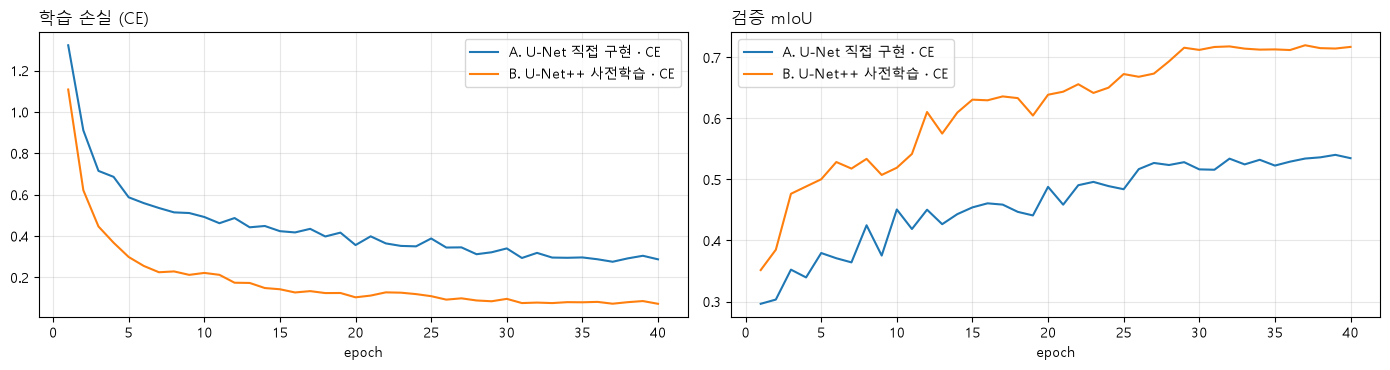

In [11]:
# 실험 1: 모델 구조 (손실은 CE로 고정)
run("A. U-Net 직접 구현 · CE", "U-Net (직접 구현)", "CE")           # 기준선
run("B. U-Net++ 사전학습 · CE", "U-Net++ (EfficientNet-B0)", "CE")  # 사전학습 인코더
# 전체 · 희소 클래스 비교
display(rare_table(["A. U-Net 직접 구현 · CE", "B. U-Net++ 사전학습 · CE"]))

# 학습 곡선
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))          # 손실 · 검증 mIoU
for name in ["A. U-Net 직접 구현 · CE", "B. U-Net++ 사전학습 · CE"]:
    h = RESULTS[name]["history"]                           # epoch 기록
    axes[0].plot(h["epoch"], h["train_loss"], label=name)  # 학습 손실
    axes[1].plot(h["epoch"], h["val_mIoU"], label=name)    # 검증 mIoU
axes[0].set_title("학습 손실 (CE)", loc="left")            # 그래프 제목
axes[1].set_title("검증 mIoU", loc="left")                 # 그래프 제목
for ax in axes:
    ax.set_xlabel("epoch")                                 # 가로축
    ax.grid(alpha=0.3)                                     # 옅은 격자
    ax.legend()                                            # 선 구분
plt.tight_layout()                                         # 제목 겹침 방지
plt.show()                                                 # 그래프 출력

**결과 해설**

```
A. U-Net 직접 구현 · CE   검증 mIoU 0.5403     : 무작위 시작, 39 epoch에서 최고
B. U-Net++ 사전학습 · CE  검증 mIoU 0.7199     : 같은 손실 · 같은 epoch에서 +0.18
Ball IoU 0.0 · 0.0                             : 두 모델 모두 공을 한 픽셀도 맞히지 못함
Referee 0.13 → 0.51 · Goalkeeper B 0.56 → 0.64 : 사전학습 인코더가 희소 클래스도 개선
학습 시간 17.6분 · 9.5분                       : U-Net++가 파라미터도 적고 학습도 빠름
```

학습 손실 그래프에서 B가 처음부터 낮게 시작 → ImageNet에서 배운 경계 · 질감 특징을 그대로 사용. 다만 CE는 픽셀 평균이라 0.1%인 공은 무시해도 손실이 거의 줄지 않음 → 실험 2에서 손실을 바꿈.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| run() · rare_table() | 사용자 정의 함수 | 실험 학습 · 희소 클래스 비교표 | `run("A. U-Net 직접 구현 · CE", ...)` |
| subplots() · plot()<br>set_title() · set_xlabel() · legend() | matplotlib | 그래프 틀 · 선<br>제목 · 축 이름 · 범례 | `axes[1].plot(h["epoch"], h["val_mIoU"], label=name)` |
| display() | IPython.display | 비교표 출력 | `display(rare_table([...]))` |
| for · 딕셔너리 키 접근 | Python 기본 문법 | 두 실험 곡선 반복 | `RESULTS[name]["history"]` |

### 3-5. 실험 2 · 손실 함수

**한글 요약**

U-Net++로 고정하고 **손실만** 바꿔 비교 (CE · CE + Dice · 가중 CE + Dice). 면적이 작은 클래스를 손실에서 어떻게 대우하느냐가 성능에 미치는 영향 확인.

**실행 흐름**

1. **입력**: 실험 1의 B(CE)
2. **처리**: CE + Dice 학습 → 가중 CE + Dice 학습 → 클래스별 IoU 비교 → 검증 mIoU 1위 선택
3. **저장**: `RESULTS`의 C · D · `BEST_LOSS`
4. **출력**: 손실별 검증 결과 · 클래스별 IoU 막대그래프

C. U-Net++ · CE + Dice       검증 mIoU 0.8361 (최고 33/40 epoch) · 학습 10.7분


D. U-Net++ · 가중 CE + Dice    검증 mIoU 0.8654 (최고 33/40 epoch) · 학습 9.4분


,검증 mIoU,Referee,Ball,Goalkeeper B
B. U-Net++ 사전학습 · CE,0.7199,0.5114,0.0000,0.6384
C. U-Net++ · CE + Dice,0.8361,0.6093,0.8887,0.7434
D. U-Net++ · 가중 CE + Dice,0.8654,0.8182,0.8443,0.7927


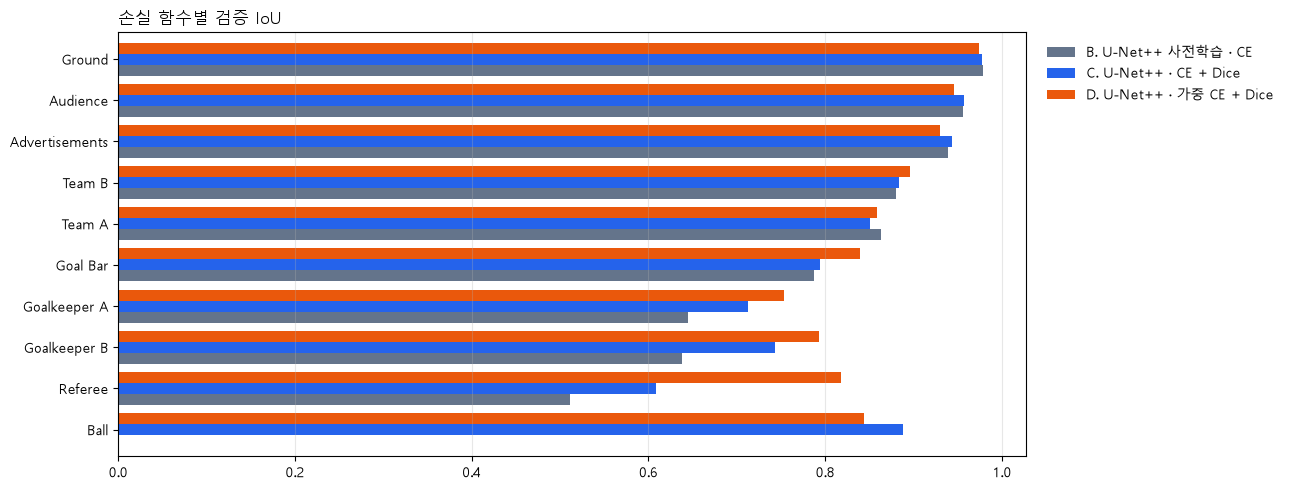

다음 실험의 기준: D. U-Net++ · 가중 CE + Dice


In [12]:
# 실험 2: 손실 함수 (모델은 U-Net++로 고정)
run("C. U-Net++ · CE + Dice", "U-Net++ (EfficientNet-B0)", "CE + Dice")  # 겹침 직접 최대화
# 희소 클래스 가중치 추가
run("D. U-Net++ · 가중 CE + Dice", "U-Net++ (EfficientNet-B0)", "가중 CE + Dice")
# 비교 대상
LOSS_RUNS = ["B. U-Net++ 사전학습 · CE", "C. U-Net++ · CE + Dice", "D. U-Net++ · 가중 CE + Dice"]
display(rare_table(LOSS_RUNS))  # 손실별 전체 · 희소 클래스 IoU

# 손실별 클래스 IoU
iou = pd.DataFrame({n: RESULTS[n]["val"]["IoU"][EVAL_CLASSES].numpy() for n in LOSS_RUNS},
                   # 낮은 클래스부터
                   index=[CLASSES[c] for c in EVAL_CLASSES]).sort_values(LOSS_RUNS[0])
# 클래스별 막대 3개
iou.plot.barh(figsize=(13, 5), width=0.8, color=["#64748b", "#2563eb", "#ea580c"])
plt.title("손실 함수별 검증 IoU", loc="left")  # 그래프 제목
plt.grid(axis="x", alpha=0.3)                  # 옅은 격자
# 범례를 그래프 밖 오른쪽에 (막대 가림 방지)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.tight_layout()                             # 겹침 방지
plt.show()                                     # 그래프 출력
# 검증 mIoU 1위 손실 → 다음 실험 기준
BEST_LOSS = max(LOSS_RUNS, key=lambda n: RESULTS[n]["val"]["mIoU"])
print("다음 실험의 기준:", BEST_LOSS)          # 선택 결과

**결과 해설**

```
B. CE              검증 mIoU 0.7199 · Ball 0.0000 : 공을 전혀 못 찾음
C. CE + Dice       검증 mIoU 0.8361 · Ball 0.8887 : 클래스별 겹침을 직접 키우자 공이 잡힘
D. 가중 CE + Dice  검증 mIoU 0.8654 · Ball 0.8443 : Referee 0.61 → 0.82 · Goalkeeper B 0.74 → 0.79
다음 실험의 기준   D                              : 검증 mIoU 1위
```

Dice는 클래스마다 '겹친 비율'을 따로 계산해 평균 → 0.1% 공도 Ground와 같은 비중. 이 한 가지 변화로 mIoU +0.116. 가중 CE를 더하면 Referee · Goalkeeper가 더 오름. 그래프에서 큰 클래스(Ground · Audience)는 세 막대 길이가 거의 같고, 차이는 아래쪽 작은 클래스에서 생김.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| DataFrame() · sort_values()<br>plot.barh() | pandas | 클래스별 IoU 표 · 정렬<br>표에서 바로 막대그래프 | `pd.DataFrame({...}).sort_values(LOSS_RUNS[0])`<br>`iou.plot.barh(figsize=(12, 5), width=0.8)` |
| title() · grid() · legend() | matplotlib | 제목 · 격자 · 범례 | `plt.legend(loc="lower right")` |
| run() · rare_table() | 사용자 정의 함수 | 손실별 학습 · 비교표 | `run("D. U-Net++ · 가중 CE + Dice", ...)` |
| max(key=) | Python 내장 함수 | 검증 mIoU 1위 손실 | `max(LOSS_RUNS, key=lambda n: ...)` |
| lambda | Python 기본 문법 | 정렬 기준 | `lambda n: RESULTS[n]["val"]["mIoU"]` |

### 3-6. 실험 3 · 희소 클래스 중심 조각

**한글 요약**

실험 2의 1위 설정에서 **학습 조각을 고르는 방법만** 바꿈. 조각의 절반은 희소 클래스(공 · 심판 · 골키퍼) 픽셀이 들어간 위치에서 잘라 작은 물체를 학습에서 더 자주 보여 줌.

**실행 흐름**

1. **입력**: `BEST_LOSS` 설정
2. **처리**: `rare_focus=0.5`로 학습 → 기준과 검증 결과 비교
3. **저장**: `RESULTS`의 E · `CANDIDATES`
4. **출력**: 기준 대비 검증 결과

In [13]:
# 실험 3: 희소 클래스 중심 조각 (손실은 실험 2의 1위로 고정)
base = RESULTS[BEST_LOSS]                                       # 기준 실험
# 조각의 절반은 희소 클래스가 들어가게
run("E. + 희소 클래스 중심 조각", base["kind"], base["loss"], rare_focus=0.5)
display(rare_table([BEST_LOSS, "E. + 희소 클래스 중심 조각"]))  # 기준 대비 변화
CANDIDATES = [BEST_LOSS, "E. + 희소 클래스 중심 조각"]          # seed 반복으로 확정할 두 설정
print("seed 반복으로 비교할 설정:", CANDIDATES)                 # 다음 단계 대상

E. + 희소 클래스 중심 조각            검증 mIoU 0.8549 (최고 28/40 epoch) · 학습 9.3분


,검증 mIoU,Referee,Ball,Goalkeeper B
D. U-Net++ · 가중 CE + Dice,0.8654,0.8182,0.8443,0.7927
E. + 희소 클래스 중심 조각,0.8549,0.8596,0.7651,0.8318


seed 반복으로 비교할 설정: ['D. U-Net++ · 가중 CE + Dice', 'E. + 희소 클래스 중심 조각']


**결과 해설**

```
D. 가중 CE + Dice           검증 mIoU 0.8654   : 기준
E. + 희소 클래스 중심 조각  검증 mIoU 0.8549   : 전체는 -0.0105
Referee 0.82 → 0.86 · Goalkeeper B 0.79 → 0.83 : 사람 희소 클래스는 상승
Ball 0.84 → 0.77                               : 공은 하락
```

seed 하나만으로는 D와 E 중 무엇이 나은지 판단할 수 없는 차이(0.01 안팎) → 두 설정 모두 seed를 바꿔 반복.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| run() · rare_table() | 사용자 정의 함수 | 희소 클래스 중심 학습 · 비교 | `run(..., rare_focus=0.5)` |
| display() · print() | IPython.display · Python 내장 함수 | 비교표 · 후보 출력 | `display(rare_table([BEST_LOSS, ...]))` |
| 키워드 인자 | Python 기본 문법 | 바꾼 조건만 이름으로 전달 | `rare_focus=0.5` |

### 3-7. seed 반복과 최종 모델 선택

**한글 요약**

- 검증 이미지가 15장뿐이라 한 번의 차이는 우연일 수 있음 → 3-6의 두 후보를 **seed 2개씩 더** 학습해 3번의 평균 · 편차로 비교
- 평균 검증 mIoU가 높은 설정에서 검증 1위 seed를 최종 모델로 선택 (**test는 여기까지 사용하지 않음**)

**실행 흐름**

1. **입력**: `CANDIDATES` 두 설정
2. **처리**: 설정 × seed(1, 2) 학습 → seed 3개 표 → 설정별 평균 ± 표준편차 → 최종 설정 · 모델 선택
3. **저장**: `seed_df` · `FINAL_CONFIG` · `FINAL_RUN`
4. **출력**: seed별 결과 · 평균 ± 표준편차 · 최종 선택

In [14]:
# 같은 설정 · 다른 seed (seed 42는 위에서 학습)
for seed in [1, 2]:
    for name in CANDIDATES:
        r = RESULTS[name]  # 설정 복사 원본
        # seed만 다르게
        run(f"{name[:1]} · seed {seed}", r["kind"], r["loss"], seed=seed, rare_focus=r["rare_focus"])

# 설정별 3개 seed 결과
rows = []                        # seed별 결과
for name in CANDIDATES:
    for key in [name, f"{name[:1]} · seed 1", f"{name[:1]} · seed 2"]:
        v = RESULTS[key]["val"]  # 검증 지표
        # 한 행
        rows.append({"설정": name, "실행": key, "검증 mIoU": v["mIoU"], **{CLASSES[c]: v["IoU"][c].item() for c in RARE}})
seed_df = pd.DataFrame(rows)     # seed 결과 표
display(seed_df.round(4))        # 개별 실행
# 설정별 평균 ± 표준편차
display(seed_df.drop(columns="실행").groupby("설정").agg(["mean", "std"]).round(4))

# 최종 모델 선택 (검증 기준)
FINAL_CONFIG = seed_df.groupby("설정")["검증 mIoU"].mean().idxmax()  # 평균 검증 mIoU가 높은 설정
# 그 설정에서 검증 1위 seed
FINAL_RUN = seed_df[seed_df["설정"] == FINAL_CONFIG].sort_values("검증 mIoU").iloc[-1]["실행"]
print("최종 설정:", FINAL_CONFIG, "| 최종 모델:", FINAL_RUN)  # 선택 결과 (test는 아직 사용 안 함)

D · seed 1                   검증 mIoU 0.8504 (최고 39/40 epoch) · 학습 9.1분


E · seed 1                   검증 mIoU 0.8538 (최고 35/40 epoch) · 학습 9.1분


D · seed 2                   검증 mIoU 0.8424 (최고 39/40 epoch) · 학습 9.1분


E · seed 2                   검증 mIoU 0.8515 (최고 30/40 epoch) · 학습 9.1분


,설정,실행,검증 mIoU,Referee,Ball,Goalkeeper B
0,D. U-Net++ · 가중 CE + Dice,D. U-Net++ · 가중 CE + Dice,0.8654,0.8182,0.8443,0.7927
1,D. U-Net++ · 가중 CE + Dice,D · seed 1,0.8504,0.8448,0.7619,0.7442
2,D. U-Net++ · 가중 CE + Dice,D · seed 2,0.8424,0.7014,0.8460,0.7644
3,E. + 희소 클래스 중심 조각,E. + 희소 클래스 중심 조각,0.8549,0.8596,0.7651,0.8318
4,E. + 희소 클래스 중심 조각,E · seed 1,0.8538,0.8502,0.7702,0.8023
5,E. + 희소 클래스 중심 조각,E · seed 2,0.8515,0.8666,0.7948,0.7885


검증 mIoU         Referee            Ball          \
                             mean     std    mean     std    mean     std   
설정                                                                          
D. U-Net++ · 가중 CE + Dice  0.8527  0.0116  0.7881  0.0763  0.8174  0.0481   
E. + 희소 클래스 중심 조각          0.8534  0.0017  0.8588  0.0082  0.7767  0.0159   

                          Goalkeeper B          
                                  mean     std  
설정                                              
D. U-Net++ · 가중 CE + Dice       0.7671  0.0244  
E. + 희소 클래스 중심 조각               0.8075  0.0221

최종 설정: E. + 희소 클래스 중심 조각 | 최종 모델: E. + 희소 클래스 중심 조각


**결과 해설**

```
D 검증 mIoU 0.8654 · 0.8504 · 0.8424 : 평균 0.8527 · 표준편차 0.0116
E 검증 mIoU 0.8549 · 0.8538 · 0.8515 : 평균 0.8534 · 표준편차 0.0017
Referee 평균 D 0.79 · E 0.86         : E가 높고 seed 간 흔들림도 작음 (표준편차 0.076 vs 0.008)
Ball 평균 D 0.82 · E 0.78            : 공은 D가 조금 높음
최종 설정 E · 최종 모델 seed 42      : 평균이 높은 설정 안에서 검증 1위
```

평균 차이는 0.0007로 사실상 같음. 차이는 안정성에서 남: E의 표준편차가 D의 약 1/7 → seed 운에 덜 좌우되는 설정. 검증이 15장뿐이라 이 정도 차이는 장 수가 늘면 뒤집힐 수 있음.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| DataFrame() · drop() · groupby() · agg()<br>idxmax() · sort_values() · iloc[] | pandas | seed 표 · 열 빼기 · 설정별 평균 · 표준편차<br>1위 설정 · 1위 seed | `seed_df.drop(columns="실행").groupby("설정").agg(["mean", "std"])`<br>`.sort_values("검증 mIoU").iloc[-1]` |
| run() | 사용자 정의 함수 | seed만 바꿔 재학습 | `run(f"{name[:1]} · seed {seed}", ..., seed=seed)` |
| 이중 for · 문자열 슬라이싱<br>** 펼치기 | Python 기본 문법 | 설정 × seed 반복 · 실험 머리글자<br>희소 클래스 열 추가 | `for seed in [1, 2]: for name in CANDIDATES:`<br>`**{CLASSES[c]: ... for c in RARE}` |

---
## 4. 평가와 오류 분석

### 4-1. test 성능

**한글 요약**

- 검증으로 고른 최종 모델을 **test 15장에서 한 번** 평가 (기준선도 같은 15장으로 비교용 확인)
- 클래스별 IoU · Dice · precision · recall로 어디가 약한지 확인
- test가 15장뿐이라 이미지를 복원 추출하는 **부트스트랩 1만 회**로 mIoU의 95% 신뢰구간 계산

**실행 흐름**

1. **입력**: `FINAL_RUN` 모델 · `split["test"]`
2. **처리**: 이미지별 혼동 행렬 → 전체 지표 · 기준선 지표 → 클래스별 표 → 부트스트랩
3. **저장**: `test_cms` · `TEST` · `final_model`
4. **출력**: test 지표 · 클래스별 표 · 신뢰구간

In [15]:
# test 평가 (최종 모델 · 비교용 기준선)
final_model = RESULTS[FINAL_RUN]["model"].to(device)               # 검증으로 고른 최종 모델
test_cms = evaluate(final_model, split["test"])                    # 이미지별 혼동 행렬
TEST = scores(sum(test_cms.values()))                              # test 15장 전체 지표
# 기준선
base_test = scores(sum(evaluate(RESULTS["A. U-Net 직접 구현 · CE"]["model"].to(device), split["test"]).values()))
RESULTS["A. U-Net 직접 구현 · CE"]["model"].cpu()                  # 기준선은 다시 CPU로
cm_total = sum(test_cms.values()).double()                         # 픽셀 정확도 계산용
print(f"최종 모델 test mIoU {TEST['mIoU']:.4f} · mDice {TEST['mDice']:.4f} · 픽셀 정확도 {cm_total.diag().sum() / cm_total.sum():.4f}")
print(f"기준선(U-Net 직접 구현 · CE) test mIoU {base_test['mIoU']:.4f} · 검증 → test 차이(최종) "
      f"{TEST['mIoU'] - RESULTS[FINAL_RUN]['val']['mIoU']:+.4f}")  # 일반화 차이

# 클래스별 지표
per_class = pd.DataFrame({k: TEST[k][EVAL_CLASSES].numpy() for k in ["IoU", "Dice", "precision", "recall"]},
                         index=[CLASSES[c] for c in EVAL_CLASSES])  # 클래스별 4개 지표
per_class["기준선 IoU"] = base_test["IoU"][EVAL_CLASSES].numpy()    # 기준선과 비교
display(per_class.sort_values("IoU").round(4))                      # 낮은 클래스부터

# 부트스트랩 95% 신뢰구간 (test 이미지를 복원 추출)
names = list(test_cms)                                      # test 이미지 15장
stack = torch.stack([test_cms[n] for n in names]).double()  # (15, 11, 11)
rng = np.random.default_rng(SEED)                           # 재현 가능한 추출
# 1만 번 다시 계산
boot = [scores(stack[rng.integers(0, len(names), len(names))].sum(0))["mIoU"] for _ in range(10_000)]
low, high = np.percentile(boot, [2.5, 97.5])                # 가운데 95% 범위
# 표본 크기에 따른 불확실성
print(f"test mIoU 95% 신뢰구간 [{low:.4f}, {high:.4f}] (이미지 15장 부트스트랩 1만 회)")

최종 모델 test mIoU 0.8240 · mDice 0.8976 · 픽셀 정확도 0.9653
기준선(U-Net 직접 구현 · CE) test mIoU 0.4661 · 검증 → test 차이(최종) -0.0309


,IoU,Dice,precision,recall,기준선 IoU
Goalkeeper B,0.5064,0.6723,0.5259,0.9318,0.1340
Referee,0.7360,0.8479,0.9114,0.7927,0.0332
Goalkeeper A,0.7710,0.8707,0.8543,0.8878,0.5711
Goal Bar,0.7916,0.8837,0.9087,0.8599,0.0978
Team A,0.8687,0.9297,0.9112,0.9490,0.6242
Team B,0.8751,0.9334,0.9117,0.9562,0.6566
Advertisements,0.8961,0.9452,0.9568,0.9339,0.7708
Ball,0.9064,0.9509,0.9171,0.9873,0.0000
Audience,0.9129,0.9544,0.9442,0.9649,0.8034
Ground,0.9758,0.9878,0.9962,0.9795,0.9700


test mIoU 95% 신뢰구간 [0.7549, 0.8511] (이미지 15장 부트스트랩 1만 회)


**결과 해설**

```
최종 test mIoU 0.8240 · mDice 0.8976    : 처음 보는 8개 장면 15장
95% 신뢰구간 [0.7549, 0.8511]           : 이미지 15장을 다시 뽑아 1만 번 계산
검증 → test 차이 -0.0309                : 검증 15장에서 고른 만큼 약간 낙관적이었음
기준선 test mIoU 0.4661                 : 같은 test에서 직접 구현 U-Net · CE
Ball IoU 0.9064 · recall 0.9873         : 기준선 0.0000 → 공을 거의 다 찾음
Goalkeeper B IoU 0.5064 · 정밀도 0.5259 : 찾기는 하지만(recall 0.93) 다른 픽셀도 B로 많이 예측
Referee IoU 0.7360 · recall 0.7927      : 심판 픽셀의 약 21%를 놓침
```

신뢰구간 폭이 약 0.10 → test 15장으로는 소수점 둘째 자리 비교가 의미 없음. 클래스별로 보면 큰 클래스(Ground 0.98 · Audience 0.91)보다 골키퍼 · 심판이 남은 과제.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| stack() · double() · sum(0) | torch | 이미지별 혼동 행렬 쌓기 · 실수 변환 · 합 | `torch.stack([test_cms[n] for n in names]).double()` |
| default_rng() · integers()<br>percentile() | numpy | 복원 추출 번호<br>2.5% · 97.5% 값 | `rng.integers(0, len(names), len(names))`<br>`np.percentile(boot, [2.5, 97.5])` |
| DataFrame() · sort_values() · round() | pandas | 클래스별 지표 표 | `per_class.sort_values("IoU").round(4)` |
| evaluate() · scores() | 사용자 정의 함수 | test 혼동 행렬 · 지표 | `scores(sum(test_cms.values()))` |
| to() · cpu() | torch.nn.Module | 평가 때만 GPU 사용 | `RESULTS[...]["model"].to(device)` |
| f-문자열 서식 :+.4f · 숫자 _ 구분 | Python 기본 문법 | 부호 있는 차이 · 10_000 | `{... :+.4f}` · `range(10_000)` |

### 4-2. 경계 오류

**한글 요약**

오류가 물체 **경계 근처**에 몰리는지 수치로 확인. 정답에서 클래스가 바뀌는 경계를 찾고, 경계에서 1 · 3 · 5 · 10픽셀 띠 안과 밖의 오류율을 비교.

<img src="images/m8_edge.png" alt="경계 띠의 면적과 그 안에 몰린 오류 비율" width="837">

**실행 흐름**

1. **입력**: 최종 모델 · test 정답
2. **처리**: 원본 크기 예측 → 정답 경계 찾기 → 반경별 띠 만들기 → 띠 안 · 밖 오류 집계
3. **저장**: `PRED` · `edge`
4. **출력**: 반경별 띠 면적 · 오류 비율 · 배율 표

In [16]:
# test 예측 마스크 (원본 크기)
data = FootballDataset(split["test"], train=False)  # 원본 그대로
PRED = {}                                           # 파일 → 예측 마스크
with torch.no_grad():
    for i, name in enumerate(split["test"]):
        x, _ = data[i]                              # i번째 이미지
        # 클래스 번호
        PRED[name] = predict(final_model, x[None].to(device)).argmax(1)[0].cpu().numpy().astype(np.uint8)


# 정답 경계 · 띠
def boundary(mask):
    valid = mask != IGNORE         # 정답 있는 픽셀
    k = np.ones((3, 3), np.uint8)  # 상하좌우 · 대각선 이웃
    # 이웃 중 가장 큰 번호 (정답 없음은 0으로 두어 무시)
    high = cv2.dilate(np.where(valid, mask, 0).astype(np.uint8), k)
    low = cv2.erode(mask, k)       # 이웃 중 가장 작은 번호 (정답 없음 255는 최솟값에 영향 없음)
    return valid & (high != low)   # 이웃과 클래스가 다르면 경계


rows = []                                                                       # 반경별 결과
for r in [1, 3, 5, 10]:
    band_n = err_band = err_all = valid_n = band_wrong = 0                      # 픽셀 수 누적
    for name in split["test"]:
        gt, pred = MASKS[name], PRED[name]                                      # 정답 · 예측
        valid = gt != IGNORE                                                    # 평가 픽셀
        # 경계에서 r픽셀 이내
        band = cv2.dilate(boundary(gt).astype(np.uint8), np.ones((2 * r + 1, 2 * r + 1), np.uint8)) > 0
        wrong = (gt != pred) & valid                                            # 틀린 픽셀
        valid_n, band_n = valid_n + valid.sum(), band_n + (band & valid).sum()  # 전체 · 띠 픽셀 수
        # 전체 · 띠 안 오류 수
        err_all, err_band = err_all + wrong.sum(), err_band + (wrong & band).sum()
    rows.append({"경계 반경(px)": r, "띠 면적 비율(%)": band_n / valid_n * 100, "띠 안 오류 비율(%)": err_band / err_all * 100,
                 "띠 오류율(%)": err_band / band_n * 100, "내부 오류율(%)": (err_all - err_band) / (valid_n - band_n) * 100})
edge = pd.DataFrame(rows)                                                       # 반경별 표
# 경계에서 몇 배 더 틀리는지
edge["배율(띠 ÷ 내부)"] = edge["띠 오류율(%)"] / edge["내부 오류율(%)"]
display(edge.round(2))                                                          # 결과 표

,경계 반경(px),띠 면적 비율(%),띠 안 오류 비율(%),띠 오류율(%),내부 오류율(%),배율(띠 ÷ 내부)
0,1,2.62,26.20,34.72,2.63,13.19
1,3,5.19,37.10,24.84,2.30,10.78
2,5,7.68,43.27,19.57,2.13,9.17
3,10,13.49,52.63,13.54,1.90,7.12


**결과 해설**

```
r = 1px  띠 면적 2.62%  · 오류의 26.20% : 오류율 34.72% vs 내부 2.63% → 13.19배
r = 5px  띠 면적 7.68%  · 오류의 43.27% : 오류율 19.57% vs 내부 2.13% → 9.17배
r = 10px 띠 면적 13.49% · 오류의 52.63% : 면적 1/7 띠에 오류 절반 이상
```

틀린 픽셀의 상당 부분이 물체 테두리에 몰림. 다만 정답도 사람이 그린 다각형이라 테두리 1~2픽셀은 정답 자체가 어긋날 수 있음(1-3의 fuse 불일치 0.07%) → 띠 오류 전부를 모델 실수로 보기는 어려움.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| dilate() · erode() | cv2 | 이웃 최댓값 · 최솟값 (경계 · 띠) | `cv2.dilate(boundary(gt).astype(np.uint8), np.ones((2 * r + 1, 2 * r + 1), np.uint8))` |
| where() · ones() · astype() | numpy | 정답 없는 픽셀 값 바꾸기 · 필터 · 형 변환 | `np.where(valid, mask, 0)` |
| argmax() · numpy() | torch.Tensor | 클래스 번호 · 배열 변환 | `predict(...).argmax(1)[0].cpu().numpy()` |
| DataFrame() · round() | pandas | 반경별 표 | `pd.DataFrame(rows)` |
| boundary() | 사용자 정의 함수 | 정답 경계 픽셀 | `boundary(gt)` |
| &amp; · ~ 불리언 연산 | Python · NumPy 연산자 | 띠 안 오류 · 정답 있는 픽셀 | <code>(wrong &amp; band).sum()</code> |

### 4-3. 혼동 행렬

**한글 요약**

정답 클래스마다 어떤 클래스로 잘못 예측됐는지 비율로 확인 (행 = 정답, 대각선 = recall). 비슷하게 생긴 클래스 사이의 혼동 찾기.

**실행 흐름**

1. **입력**: `test_cms`
2. **처리**: test 전체 혼동 행렬 → 행 정규화 → 그림 → 대각선 밖 상위 6쌍
3. **저장**: 없음
4. **출력**: 혼동 행렬 그림 · 가장 많이 헷갈린 쌍

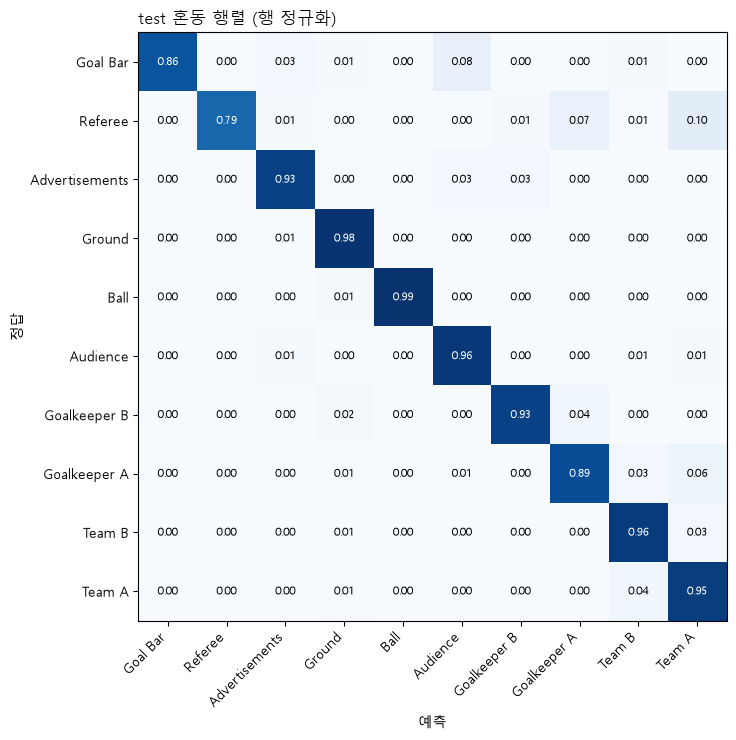

,정답,예측,정답 픽셀 중 비율
0,Referee,Team A,0.1020
1,Goal Bar,Audience,0.0814
2,Referee,Goalkeeper A,0.0679
3,Goalkeeper A,Team A,0.0596
4,Team A,Team B,0.0377
5,Goalkeeper B,Goalkeeper A,0.0374


In [17]:
# 행 정규화 혼동 행렬 (정답 기준)
cm = sum(test_cms.values()).double()[EVAL_CLASSES][:, EVAL_CLASSES]  # 평가 클래스만
norm = cm / cm.sum(1, keepdim=True)                                 # 각 행 합 = 1 (대각선 = recall)
labels = [CLASSES[c] for c in EVAL_CLASSES]                         # 축 이름
fig, ax = plt.subplots(figsize=(9, 7.5))                            # 정사각형에 가깝게
ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)                       # 색 = 비율
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if norm[i, j] > 0.5 else "black")     # 칸마다 비율
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")  # 예측 클래스
ax.set_yticks(range(len(labels)), labels)                           # 정답 클래스
ax.set_xlabel("예측")                                               # 가로축
ax.set_ylabel("정답")                                               # 세로축
ax.set_title("test 혼동 행렬 (행 정규화)", loc="left")              # 제목
plt.tight_layout()                                                  # 겹침 방지
plt.show()                                                          # 그림 출력

# 가장 많이 헷갈린 쌍
# 대각선 밖
off = [(labels[i], labels[j], norm[i, j].item()) for i in range(len(labels)) for j in range(len(labels)) if i != j]
# 상위 6쌍
display(pd.DataFrame(sorted(off, key=lambda t: -t[2])[:6], columns=["정답", "예측", "정답 픽셀 중 비율"]).round(4))

**결과 해설**

```
Referee → Team A 10.2%           : 심판 픽셀 10%를 A팀으로 (둘 다 사람 · 비슷한 위치)
Goal Bar → Audience 8.1%         : 가는 골대 기둥이 뒤 관중석으로
Referee → Goalkeeper A 6.8%      : 사람끼리 혼동
Goalkeeper A → Team A 6.0%       : 골키퍼를 선수로
Goalkeeper B → Goalkeeper A 3.7% : 두 팀 골키퍼끼리
```

혼동은 대부분 '사람 ↔ 사람' 사이에서 생김. 모양으로는 구분이 안 되고 유니폼 색으로만 갈리는 클래스들 → 색이 비슷하거나 작게 찍히면 틀림.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| imshow() · text()<br>set_xticks() · set_yticks() | matplotlib | 혼동 행렬 색 · 칸 숫자<br>축 클래스 이름 | `ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)`<br>`ax.set_xticks(range(len(labels)), labels, rotation=45)` |
| sum(1, keepdim=True) | torch.Tensor | 행 합으로 나누기 | `cm / cm.sum(1, keepdim=True)` |
| sorted(key=) | Python 내장 함수 | 비율 큰 순서 | `sorted(off, key=lambda t: -t[2])[:6]` |
| 이중 컴프리헨션 · 인덱싱 [ ][:, ] | Python 기본 문법 | 대각선 밖 칸 모으기 · 평가 클래스 행 · 열 | `[...][EVAL_CLASSES][:, EVAL_CLASSES]` |

### 4-4. 오류 사례와 공

**한글 요약**

- 이미지별 mIoU로 가장 어려운 · 쉬운 test 장면을 골라 원본 · 정답 · 예측 · 오류를 나란히 비교
- 가장 작은 클래스인 **공**은 전체 그림에서 보이지 않으므로 공 주변 160×160을 확대해 확인

**실행 흐름**

1. **입력**: `test_cms` · `PRED`
2. **처리**: 이미지별 mIoU → 최저 · 최고 이미지 4칸 그림 → 공이 있는 이미지마다 확대 · 공 recall
3. **저장**: `img_miou`
4. **출력**: 이미지별 mIoU 요약 · 사례 그림 · 공 확대 그림

이미지별 mIoU 최저 0.6313 · 중앙값 0.8963 · 최고 0.9279


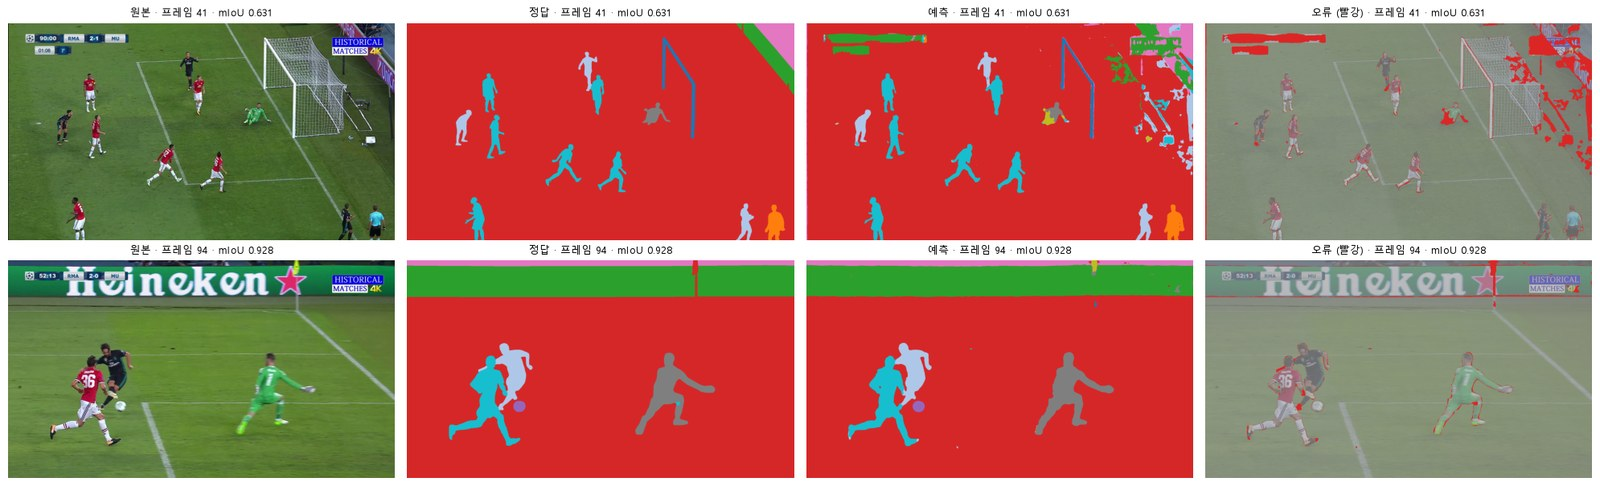

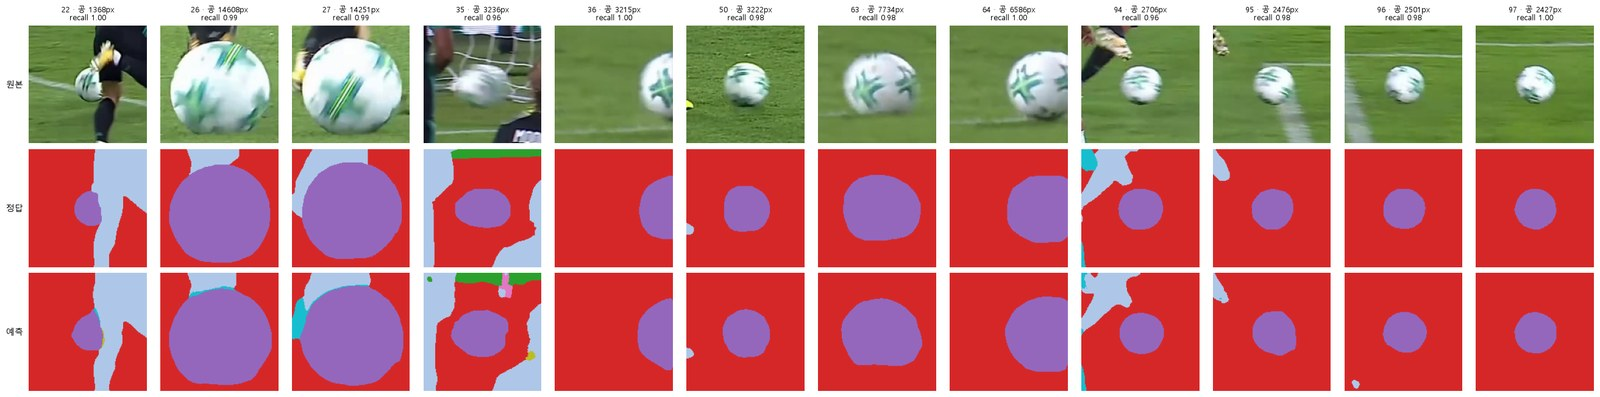

In [18]:
# 이미지별 mIoU
img_miou = pd.Series({n: np.nanmean([scores(test_cms[n])["IoU"][c].item() for c in EVAL_CLASSES if test_cms[n][c].sum() > 0])
                      for n in split["test"]})  # 그 이미지에 나온 클래스만 평균
# 분포 요약
print(f"이미지별 mIoU 최저 {img_miou.min():.4f} · 중앙값 {img_miou.median():.4f} · 최고 {img_miou.max():.4f}")


def error_map(name):
    gt, pred = MASKS[name], PRED[name]                        # 정답 · 예측
    out = (IMAGES[name] * 0.35 + 255 * 0.4).astype(np.uint8)  # 흐린 원본 위에
    out[(gt != pred) & (gt != IGNORE)] = [220, 38, 38]        # 틀린 픽셀 빨강
    return out


# 최저 · 최고 이미지 비교
show = [img_miou.idxmin(), img_miou.idxmax()]      # 가장 어려운 장면 · 가장 쉬운 장면
fig, axes = plt.subplots(2, 4, figsize=(20, 6.2))  # 행 = 이미지
for row, name in zip(axes, show):
    for ax, img, title in zip(row, [IMAGES[name], colorize(MASKS[name]), colorize(PRED[name]), error_map(name)],
                              ["원본", "정답", "예측", "오류 (빨강)"]):
        ax.imshow(img)                             # 그림 출력
        # 이미지 정보
        ax.set_title(f"{title} · 프레임 {frame_no(name)} · mIoU {img_miou[name]:.3f}", fontsize=9)
        ax.axis("off")                             # 축 숨김
plt.tight_layout()                                 # 겹침 방지
plt.show()                                         # 그림 출력

# 공 확대 (정답 공 주변 160×160)
ball = CLASSES.index("Ball")                                                # 공 클래스 번호
balls = [n for n in split["test"] if (MASKS[n] == ball).any()]              # 공이 있는 test 이미지
# 열 = 이미지
fig, axes = plt.subplots(3, len(balls), figsize=(2.2 * len(balls), 6.6), squeeze=False)
for k, name in enumerate(balls):
    ys, xs = np.nonzero(MASKS[name] == ball)                                # 공 픽셀 위치
    cy, cx = int(ys.mean()), int(xs.mean())                                 # 공 중심
    y0, x0 = np.clip(cy - 80, 0, 1080 - 160), np.clip(cx - 80, 0, 1920 - 160)  # 확대 범위
    hit = (PRED[name][MASKS[name] == ball] == ball).mean()                  # 공 픽셀 중 맞힌 비율
    for row, img in enumerate([IMAGES[name], colorize(MASKS[name]), colorize(PRED[name])]):
        axes[row, k].imshow(img[y0:y0 + 160, x0:x0 + 160])                  # 확대 그림
        axes[row, k].axis("off")                                            # 축 숨김
    # 크기 · 맞힌 비율
    axes[0, k].set_title(f"{frame_no(name)} · 공 {(MASKS[name] == ball).sum()}px\nrecall {hit:.2f}", fontsize=9)
for row, label in enumerate(["원본", "정답", "예측"]):
    axes[row, 0].text(-8, 80, label, ha="right", va="center", fontsize=10)  # 행 이름
plt.tight_layout()                                                          # 겹침 방지
plt.show()                                                                  # 그림 출력

**결과 해설**

```
이미지별 mIoU 최저 0.6313 · 중앙값 0.8963 · 최고 0.9279
최저 프레임 41 : 멀리서 찍은 넓은 화면, 작은 선수 · 그물 · 방송 자막
최고 프레임 94 : 가까운 화면, 큰 선수 · 단순한 배경
공 확대 12장   : 공 크기 1,368 ~ 14,608픽셀 · recall 0.96 ~ 1.00
```

최저 프레임에서는 Goalkeeper B(회색) 일부가 A(올리브색)로, 방송 자막 · 그물 주변이 광고판 · 관중으로 칠해짐. 공은 test에 나온 12장 모두에서 테두리만 조금 다르고 위치 · 모양은 거의 맞음 → 기준선에서 0이던 공이 가장 크게 개선된 클래스.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Series() · idxmin() · idxmax() · median() | pandas | 이미지별 mIoU · 최저 · 최고 · 중앙값 | `img_miou.idxmin()` |
| nanmean() · nonzero() · clip() | numpy | 나온 클래스만 평균 · 공 위치 · 확대 범위 | `np.nonzero(MASKS[name] == ball)` |
| subplots(squeeze=False) · text() | matplotlib | 열이 1개여도 2차원 · 행 이름 | `plt.subplots(3, len(balls), ..., squeeze=False)` |
| error_map() | 사용자 정의 함수 | 틀린 픽셀 빨강 표시 | `error_map(name)` |
| zip() · enumerate() | Python 내장 함수 | 그림 칸 · 이미지 짝짓기 | `zip(row, [IMAGES[name], ...], [...])` |
| 불리언 인덱싱 · \n 줄바꿈 | Python · NumPy 문법 | 틀린 픽셀만 색칠 · 제목 두 줄 | `out[(gt != pred) & ...] = [220, 38, 38]` |

---
## 5. 마무리

### 최종 결과

| 항목 | 결과 |
| :-- | :-- |
| **최종 모델** | U-Net++ (EfficientNet-B0, ImageNet 사전학습) · 가중 CE + Dice · 희소 클래스 중심 조각 50% · AdamW 40 epoch · seed 42 (검증 기준 선택) |
| **test** (8개 장면 15장, 한 번만 평가) | mIoU **0.8240** (95% 신뢰구간 0.7549 ~ 0.8511) · mDice **0.8976** · 픽셀 정확도 0.9653 |
| **기준선** (직접 구현 U-Net · CE) | test mIoU 0.4661 → 최종 모델 +0.3579 |
| **희소 클래스 test IoU** | Ball **0.9064** · Referee 0.7360 · Goalkeeper B 0.5064 |

### 핵심 결과

- **정답부터 확인해야 학습 가능**: fuse 색 11개 중 JSON 색과 일치 0개 → 클래스 번호가 있는 다각형으로 정답 생성, fuse와 99.93% 일치 확인
- **연속 프레임은 장면 단위로**: 프레임 16과 98이 같은 장면 → 장면 46개를 쪼개지 않고 나눠 test 부풀림 방지
- **사전학습이 기반, 손실이 공을 살림**: U-Net++로 검증 +0.18, Dice를 더해 공 IoU 0 → 0.89
- **seed 하나로는 결론 불가**: 실험 3의 D · E 차이(0.0105)가 seed 3개 평균에서 0.0007로 줄어듦 → 평균이 같으면 흔들림이 작은 E 선택
- **남은 약점은 테두리와 사람끼리**: 오류의 43%가 면적 7.7% 경계 띠에, 혼동은 심판 · 골키퍼 · 선수 사이에서

### 재현성 확인

같은 코드 · 같은 seed로 전체 노트북을 두 번 실행해 비교. 2차 실행 전에 바꾼 것은 3-5 그래프의 범례 위치(막대를 가리지 않게 그래프 밖으로)뿐이고 학습 코드는 같음.

| 항목 | 1차 실행 | 2차 실행 (이 노트북) |
| :-- | :-- | :-- |
| 데이터 점검 · 분할 (1 · 2장) | 같음 | 같음 |
| A · B · C 검증 mIoU | 0.5403 · 0.7199 · 0.8361 | 0.5403 · 0.7199 · 0.8361 |
| D 검증 mIoU (seed 42) | 0.8484 | 0.8654 |
| E 검증 mIoU (seed 42) | 0.8540 | 0.8549 |
| seed 3개 평균 D · E | 0.8388 · 0.8613 | 0.8527 · 0.8534 |
| 최종 설정 · 선택된 seed | E · seed 2 | E · seed 42 |
| test mIoU (95% 신뢰구간) | 0.7577 (0.7137 ~ 0.8003) | **0.8240** (0.7549 ~ 0.8511) |
| test Ball · Goalkeeper B IoU | 0.8692 · 0.3048 | 0.9064 · 0.5064 |

- **클래스 가중치가 없는 손실(A · B · C)은 두 실행이 소수점 넷째 자리까지 같음**. 가중 CE가 들어간 D · E부터 달라짐 → 가중치가 붙은 손실 계산이 GPU에서 실행마다 미세하게 다른 값을 내고, 이 차이가 40 epoch 동안 커진 것으로 추정 (원인을 따로 검증하지는 않음)
- **두 실행 모두 같은 결론**: 최종 설정은 E, 가장 큰 개선은 CE → CE + Dice, test 공 IoU 0.87 이상
- **달라진 것은 선택된 seed와 test 점수**: 검증 15장으로 seed를 고르면 실행마다 다른 seed가 뽑히고, test mIoU가 0.758 ~ 0.824로 움직임. 두 신뢰구간이 겹치므로 test 15장으로는 이 차이를 가를 수 없음 → **최종 성능은 '0.76 ~ 0.82 수준'으로 읽는 것이 정확**

### 다음 단계

- **검증 늘리기**: 장면 단위 5겹 교차검증으로 test 외 84장을 모두 검증에 써서 설정 · seed 선택의 흔들림 감소
- **골키퍼 · 심판 구분**: 유니폼 색이 핵심 단서 → 밝기 · 대비 증강 폭을 줄이거나, 사람 영역을 먼저 찾고 색으로 다시 분류하는 2단계 방식 비교
- **경계 다듬기**: 경계 가중 손실 · Lovász 손실 비교, 경계 1~2px를 평가에서 제외한 점수도 함께 보고 (정답 다각형 오차 분리)
- **결정적 학습 확인**: `torch.use_deterministic_algorithms(True)`로 가중 CE의 실행 간 차이가 사라지는지 확인

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **1. 데이터 점검** | 색 · 중복 · 장면 · 정답 마스크 · 분포 | fuse 색 일치 0개, 중복 14 = 71, 장면 46개, 공 0.115% |
| **2. 데이터 준비** | 장면 단위 분할, 512 조각 증강 | train 69 · val 15 · test 15, 장면 겹침 없음 |
| **3. 모델과 학습** | 모델 → 손실 → 조각 → seed 순서로 한 가지씩 | 검증 0.540 → 0.720 → 0.865, seed 평균 D 0.853 · E 0.853 |
| **4. 평가** | test 한 번 · 신뢰구간 · 경계 · 혼동 · 오류 사례 | test 0.824 [0.755, 0.851], 경계 띠에 오류 43% |
| **5. 마무리** | 두 번 실행해 재현성 확인 | 결론 같음, test는 0.758 ~ 0.824 |